In [2]:
from pathlib import Path

DATASET_PATH = Path("/Users/iremkeser/rtdetr_reproduction/RT-DETR/data/raw/pcb-defect-dataset")

for path in sorted(DATASET_PATH.iterdir()):
    print(
        path.name
    )

data.yaml
test
train
val


In [3]:
from pathlib import Path

for split in ["train", "val", "test"]:
    split_path = DATASET_PATH / split

    print(f"\n{'=' * 35}")
    print(split.upper())
    print(f"{'=' * 35}")

    if not split_path.exists():
        print("Klasör bulunamadı!")
        continue

    for item in sorted(split_path.iterdir()):
        print("📁" if item.is_dir() else "📄", item.name)

        if item.is_dir():
            print("   Dosya sayısı:", len(list(item.iterdir())))


TRAIN
📁 images
   Dosya sayısı: 8534
📁 labels
   Dosya sayısı: 8534

VAL
📁 images
   Dosya sayısı: 1066
📁 labels
   Dosya sayısı: 1066

TEST
📁 images
   Dosya sayısı: 1068
📁 labels
   Dosya sayısı: 1068


In [4]:
import yaml

yaml_path = DATASET_PATH / "data.yaml"

with open(yaml_path, "r", encoding="utf-8") as f:
    data_config = yaml.safe_load(f)

print("DATASET CONFIGURATION")
print("-" * 40)

for key, value in data_config.items():
    print(f"{key}: {value}")

DATASET CONFIGURATION
----------------------------------------
path: ../pcb-defect-dataset
train: train
val: val
test: test
names: {0: 'mouse_bite', 1: 'spur', 2: 'missing_hole', 3: 'short', 4: 'open_circuit', 5: 'spurious_copper'}


In [5]:
import pandas as pd

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

rows = []

for split in ["train", "val", "test"]:
    split_path = DATASET_PATH / split

    image_files = [
        p for p in split_path.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    label_files = [
        p for p in split_path.rglob("*.txt")
        if p.is_file()
    ]

    rows.append({
        "split": split,
        "images": len(image_files),
        "label_files": len(label_files)
    })

dataset_summary = pd.DataFrame(rows)

display(dataset_summary)

,split,images,label_files
0,train,8534,8534
1,val,1066,1066
2,test,1068,1068


In [6]:
import pandas as pd

CLASS_NAMES = data_config["names"]

def load_yolo_annotations(dataset_path, split):
    labels_dir = dataset_path / split / "labels"
    images_dir = dataset_path / split / "images"

    rows = []
    image_stats = []

    for label_path in sorted(labels_dir.glob("*.txt")):
        image_id = label_path.stem

        lines = label_path.read_text().strip().splitlines()

        image_stats.append({
            "image_id": image_id,
            "object_count": len(lines),
            "is_positive": len(lines) > 0
        })

        for line in lines:
            values = line.split()

            if len(values) != 5:
                print("Beklenmeyen anotasyon:", label_path.name, line)
                continue

            class_id = int(values[0])
            x_center, y_center, width, height = map(float, values[1:])

            rows.append({
                "image_id": image_id,
                "class_id": class_id,
                "class_name": CLASS_NAMES[class_id],
                "x_center": x_center,
                "y_center": y_center,
                "bbox_width": width,
                "bbox_height": height
            })

    annotations_df = pd.DataFrame(rows)
    images_df = pd.DataFrame(image_stats)

    return annotations_df, images_df


train_objects, train_images = load_yolo_annotations(DATASET_PATH, "train")
val_objects, val_images = load_yolo_annotations(DATASET_PATH, "val")
test_objects, test_images = load_yolo_annotations(DATASET_PATH, "test")

print("Train objects:", len(train_objects))
print("Val objects:", len(val_objects))
print("Test objects:", len(test_objects))

display(train_objects.head())

Train objects: 17342
Val objects: 2164
Test objects: 2158


,image_id,class_id,class_name,x_center,y_center,bbox_width,bbox_height
0,l_light_01_missing_hole_01_1_600,2,missing_hole,0.4350,0.7008,0.0700,0.0550
1,l_light_01_missing_hole_01_2_600,2,missing_hole,0.6367,0.0508,0.0667,0.0617
2,l_light_01_missing_hole_01_2_600,2,missing_hole,0.7575,0.5333,0.0717,0.0600
3,l_light_01_missing_hole_02_1_600,2,missing_hole,0.5633,0.2783,0.0667,0.0667
4,l_light_01_missing_hole_02_1_600,2,missing_hole,0.3208,0.8733,0.0383,0.0567


In [7]:
def analyze_image_distribution(images_df, split):
    total = len(images_df)

    positive = (images_df["object_count"] > 0).sum()
    negative = (images_df["object_count"] == 0).sum()

    positive_counts = images_df.loc[
        images_df["object_count"] > 0, "object_count"
    ]

    return {
        "split": split,
        "total_images": total,
        "positive_images": positive,
        "negative_images": negative,
        "positive_ratio_%": round(100 * positive / total, 2),
        "negative_ratio_%": round(100 * negative / total, 2),
        "mean_objects_positive": round(positive_counts.mean(), 2),
        "median_objects_positive": positive_counts.median(),
        "max_objects": images_df["object_count"].max()
    }


distribution = pd.DataFrame([
    analyze_image_distribution(train_images, "train"),
    analyze_image_distribution(val_images, "val"),
    analyze_image_distribution(test_images, "test")
])

display(distribution)

,split,total_images,positive_images,negative_images,positive_ratio_%,negative_ratio_%,mean_objects_positive,median_objects_positive,max_objects
0,train,8534,8534,0,100.0,0.0,2.03,2.0,5
1,val,1066,1066,0,100.0,0.0,2.03,2.0,5
2,test,1068,1068,0,100.0,0.0,2.02,2.0,5


In [8]:
class_distribution = (
    train_objects
    .groupby(["class_id", "class_name"])
    .agg(
        total_objects=("image_id", "size"),
        positive_images=("image_id", "nunique")
    )
    .reset_index()
)

class_distribution["objects_per_positive_image"] = (
    class_distribution["total_objects"]
    / class_distribution["positive_images"]
)

display(class_distribution.round(2))

,class_id,class_name,total_objects,positive_images,objects_per_positive_image
0,0,mouse_bite,2980,1501,1.99
1,1,spur,2919,1404,2.08
2,2,missing_hole,2902,1477,1.96
3,3,short,2731,1347,2.03
4,4,open_circuit,2844,1396,2.04
5,5,spurious_copper,2966,1409,2.11


In [9]:
def analyze_per_class(objects_df, images_df, split):
    total_images = len(images_df)
    rows = []

    for class_id, class_name in CLASS_NAMES.items():

        class_objects = objects_df[
            objects_df["class_id"] == class_id
        ]

        positive_images = class_objects["image_id"].nunique()
        negative_images = total_images - positive_images

        mean_objects = (
            len(class_objects) / positive_images
            if positive_images > 0 else 0
        )

        rows.append({
            "split": split,
            "class": class_name,
            "total_objects": len(class_objects),
            "positive_images": positive_images,
            "negative_images": negative_images,
            "positive_ratio_%": round(
                100 * positive_images / total_images, 2
            ),
            "mean_objects_positive": round(mean_objects, 2)
        })

    return pd.DataFrame(rows)


per_class_distribution = pd.concat([
    analyze_per_class(train_objects, train_images, "train"),
    analyze_per_class(val_objects, val_images, "val"),
    analyze_per_class(test_objects, test_images, "test")
], ignore_index=True)

display(per_class_distribution)

,split,class,total_objects,positive_images,negative_images,positive_ratio_%,mean_objects_positive
0,train,mouse_bite,2980,1501,7033,17.59,1.99
1,train,spur,2919,1404,7130,16.45,2.08
2,train,missing_hole,2902,1477,7057,17.31,1.96
3,train,short,2731,1347,7187,15.78,2.03
4,train,open_circuit,2844,1396,7138,16.36,2.04
5,train,spurious_copper,2966,1409,7125,16.51,2.11
6,val,mouse_bite,372,183,883,17.17,2.03
7,val,spur,369,179,887,16.79,2.06
8,val,missing_hole,331,165,901,15.48,2.01
9,val,short,411,201,865,18.86,2.04


In [10]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import random

def show_annotated_image(split, image_id):
    images_dir = DATASET_PATH / split / "images"
    label_path = DATASET_PATH / split / "labels" / f"{image_id}.txt"

    image_path = next(
        (p for p in images_dir.glob(f"{image_id}.*")
         if p.suffix.lower() in {".jpg", ".jpeg", ".png"}),
        None
    )

    if image_path is None:
        print("Görüntü bulunamadı:", image_id)
        return

    image = Image.open(image_path).convert("RGB")
    img_w, img_h = image.size

    fig, ax = plt.subplots(figsize=(9, 7))
    ax.imshow(image)

    with open(label_path, "r") as f:
        lines = f.readlines()

    for line in lines:
        values = line.strip().split()
        if len(values) != 5:
            continue

        class_id = int(values[0])
        xc, yc, w, h = map(float, values[1:])

        # Normalize YOLO koordinatlarını piksele çevir
        box_w = w * img_w
        box_h = h * img_h

        x1 = xc * img_w - box_w / 2
        y1 = yc * img_h - box_h / 2

        rect = patches.Rectangle(
            (x1, y1),
            box_w,
            box_h,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rect)

        ax.text(
            x1,
            max(y1 - 4, 0),
            CLASS_NAMES[class_id],
            color="white",
            fontsize=9,
            bbox=dict(facecolor="red", alpha=0.8, pad=2)
        )

    ax.set_title(f"{split.upper()} — {image_id}")
    ax.axis("off")
    plt.show()

In [11]:
image_name = "light_12_spurious_copper_08_5_600.jpg"

image_id = Path(image_name).stem

label_path = DATASET_PATH / "val" / "labels" / f"{image_id}.txt"

print("Label dosyası mevcut mu?", label_path.exists())

if label_path.exists():
    content = label_path.read_text().strip()

    print("Label içeriği:")
    print(content if content else "(BOŞ)")

    print("Anotasyon sayısı:", len(content.splitlines()) if content else 0)

Label dosyası mevcut mu? False


In [12]:
from pathlib import Path

image_name = "light_12_spurious_copper_08_5_600.jpg"
image_id = Path(image_name).stem

# Dosya adının bir kısmıyla arama yap
keyword = "spurious_copper_08_5_600"

matches = [
    p for p in DATASET_PATH.rglob("*")
    if p.is_file() and keyword in p.name
]

print("Bulunan dosyalar:", len(matches))

for p in matches:
    print(p.relative_to(DATASET_PATH))

Bulunan dosyalar: 28
test/images/rotation_270_light_12_spurious_copper_08_5_600.jpg
test/labels/rotation_270_light_12_spurious_copper_08_5_600.txt
train/images/l_light_08_spurious_copper_08_5_600.jpg
train/images/rotation_90_light_12_spurious_copper_08_5_600.jpg
train/images/rotation_90_light_07_spurious_copper_08_5_600.jpg
train/images/light_08_spurious_copper_08_5_600.jpg
train/images/rotation_270_light_07_spurious_copper_08_5_600.jpg
train/images/rotation_270_light_09_spurious_copper_08_5_600.jpg
train/images/light_07_spurious_copper_08_5_600.jpg
train/images/light_09_spurious_copper_08_5_600.jpg
train/images/rotation_90_light_08_spurious_copper_08_5_600.jpg
train/images/l_light_07_spurious_copper_08_5_600.jpg
train/images/l_light_09_spurious_copper_08_5_600.jpg
train/images/l_light_12_spurious_copper_08_5_600.jpg
train/labels/l_light_08_spurious_copper_08_5_600.txt
train/labels/rotation_90_light_12_spurious_copper_08_5_600.txt
train/labels/rotation_90_light_07_spurious_copper_08_5_

In [13]:
import pandas as pd

def check_annotation_status(dataset_path, split):
    images_dir = dataset_path / split / "images"
    labels_dir = dataset_path / split / "labels"

    image_files = {
        p.stem: p
        for p in images_dir.iterdir()
        if p.suffix.lower() in {
            ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"
        }
    }

    label_files = {
        p.stem: p
        for p in labels_dir.glob("*.txt")
    }

    rows = []

    for image_id in image_files:
        label_path = label_files.get(image_id)

        if label_path is None:
            status = "missing_label"
        elif not label_path.read_text().strip():
            status = "empty_label"
        else:
            status = "annotated"

        rows.append({
            "split": split,
            "image_id": image_id,
            "status": status
        })

    return pd.DataFrame(rows)


annotation_status = pd.concat([
    check_annotation_status(DATASET_PATH, split)
    for split in ["train", "val", "test"]
], ignore_index=True)

summary = pd.crosstab(
    annotation_status["split"],
    annotation_status["status"]
)

summary["total"] = summary.sum(axis=1)

display(summary)

print("\nTOPLAM:")
print(annotation_status["status"].value_counts())

status,annotated,missing_label,total
split,,,
test,829,239,1068
train,6370,2164,8534
val,802,264,1066



TOPLAM:
status
annotated        8001
missing_label    2667
Name: count, dtype: int64


In [14]:
def get_variant(image_id):
    if image_id.startswith("rotation_90_"):
        return "rotation_90"
    elif image_id.startswith("rotation_270_"):
        return "rotation_270"
    elif image_id.startswith("l_"):
        return "l_variant"
    else:
        return "original_or_other"


annotation_status["variant"] = (
    annotation_status["image_id"].apply(get_variant)
)

variant_summary = pd.crosstab(
    [annotation_status["split"], annotation_status["variant"]],
    annotation_status["status"]
)

variant_summary["total"] = variant_summary.sum(axis=1)

variant_summary["missing_%"] = (
    variant_summary["missing_label"]
    / variant_summary["total"] * 100
).round(2)

display(variant_summary)

status                   annotated  missing_label  total  missing_%
split variant                                                      
test  l_variant                281              0    281        0.0
      original_or_other          0            239    239      100.0
      rotation_270             277              0    277        0.0
      rotation_90              271              0    271        0.0
train l_variant               2106              0   2106        0.0
      original_or_other          0           2164   2164      100.0
      rotation_270            2117              0   2117        0.0
      rotation_90             2147              0   2147        0.0
val   l_variant                280              0    280        0.0
      original_or_other          0            264    264      100.0
      rotation_270             273              0    273        0.0
      rotation_90              249              0    249        0.0

In [15]:
def get_base_id(image_id):
    for prefix in ["rotation_90_", "rotation_270_", "l_"]:
        if image_id.startswith(prefix):
            return image_id[len(prefix):]
    return image_id


annotation_status["base_id"] = (
    annotation_status["image_id"].apply(get_base_id)
)

# Aynı kaynak görüntünün kaç farklı varyasyonu var?
base_summary = (
    annotation_status
    .groupby("base_id")
    .agg(
        image_count=("image_id", "size"),
        split_count=("split", "nunique"),
        annotated_count=("status", lambda x: (x == "annotated").sum()),
        missing_count=("status", lambda x: (x == "missing_label").sum())
    )
    .reset_index()
)

print("Benzersiz kaynak görüntü:", len(base_summary))

print("\nKaynak başına görüntü sayısı:")
display(base_summary["image_count"].value_counts().sort_index())

print("\nBirden fazla split'te bulunan kaynak görüntü:")
print((base_summary["split_count"] > 1).sum())

print("\nÖrnekler:")
display(base_summary.head(10))

Benzersiz kaynak görüntü: 2667

Kaynak başına görüntü sayısı:


image_count
4    2667
Name: count, dtype: int64


Birden fazla split'te bulunan kaynak görüntü:
1556

Örnekler:


,base_id,image_count,split_count,annotated_count,missing_count
0,light_01_missing_hole_01_1_600,4,1,3,1
1,light_01_missing_hole_01_2_600,4,2,3,1
2,light_01_missing_hole_02_1_600,4,1,3,1
3,light_01_missing_hole_02_2_600,4,2,3,1
4,light_01_missing_hole_02_3_600,4,2,3,1
5,light_01_missing_hole_03_1_600,4,2,3,1
6,light_01_missing_hole_03_2_600,4,2,3,1
7,light_01_missing_hole_04_1_600,4,1,3,1
8,light_01_missing_hole_04_2_600,4,2,3,1
9,light_01_missing_hole_05_1_600,4,2,3,1


In [16]:
from sklearn.model_selection import train_test_split

# Yalnızca anotasyonu bulunan görüntüler
df = annotation_status[
    annotation_status["status"] == "annotated"
].copy()

# Benzersiz kaynak görüntüler
base_ids = df["base_id"].unique()

# %80 train, %20 geçici
train_ids, temp_ids = train_test_split(
    base_ids,
    test_size=0.20,
    random_state=42
)

# %10 validation, %10 test
val_ids, test_ids = train_test_split(
    temp_ids,
    test_size=0.50,
    random_state=42
)

split_map = {
    **{x: "train" for x in train_ids},
    **{x: "val" for x in val_ids},
    **{x: "test" for x in test_ids}
}

df["new_split"] = df["base_id"].map(split_map)

print("Yeni split dağılımı:")
print(df["new_split"].value_counts())

print("\nKaynak ID sayıları:")
print(df.groupby("new_split")["base_id"].nunique())

# Leakage kontrolü
groups = [
    set(df.loc[df["new_split"] == split, "base_id"])
    for split in ["train", "val", "test"]
]

assert not (groups[0] & groups[1])
assert not (groups[0] & groups[2])
assert not (groups[1] & groups[2])

print("\nLeakage kontrolü: BAŞARILI")

Yeni split dağılımı:
new_split
train    6399
test      801
val       801
Name: count, dtype: int64

Kaynak ID sayıları:
new_split
test      267
train    2133
val       267
Name: base_id, dtype: int64

Leakage kontrolü: BAŞARILI


In [17]:
import shutil
from pathlib import Path

OUTPUT_PATH = DATASET_PATH.parent / "pcb_clean_split"

for split in ["train", "val", "test"]:
    (OUTPUT_PATH / split / "images").mkdir(
        parents=True, exist_ok=True
    )
    (OUTPUT_PATH / split / "labels").mkdir(
        parents=True, exist_ok=True
    )

copied = 0

for _, row in df.iterrows():
    old_split = row["split"]
    new_split = row["new_split"]
    image_id = row["image_id"]

    # Kaynak görüntüyü bul
    source_images = list(
        (DATASET_PATH / old_split / "images").glob(f"{image_id}.*")
    )

    if len(source_images) != 1:
        raise ValueError(f"Görüntü bulunamadı veya birden fazla: {image_id}")

    source_image = source_images[0]

    source_label = (
        DATASET_PATH / old_split / "labels" / f"{image_id}.txt"
    )

    if not source_label.exists():
        raise FileNotFoundError(source_label)

    # Hedef yollar
    target_image = (
        OUTPUT_PATH / new_split / "images" / source_image.name
    )

    target_label = (
        OUTPUT_PATH / new_split / "labels" / source_label.name
    )

    shutil.copy2(source_image, target_image)
    shutil.copy2(source_label, target_label)

    copied += 1

print(f"Kopyalanan görüntü sayısı: {copied}")
print(f"Yeni veri seti: {OUTPUT_PATH}")

Kopyalanan görüntü sayısı: 8001
Yeni veri seti: /Users/iremkeser/rtdetr_reproduction/RT-DETR/data/raw/pcb_clean_split


In [18]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Yeniden oluşturduğumuz veri seti
EDA_PATH = OUTPUT_PATH

CLASS_NAMES = {
    0: "mouse_bite",
    1: "spur",
    2: "missing_hole",
    3: "short",
    4: "open_circuit",
    5: "spurious_copper"
}

print("Dataset:", EDA_PATH)
print("Dataset mevcut mu?", EDA_PATH.exists())

Dataset: /Users/iremkeser/rtdetr_reproduction/RT-DETR/data/raw/pcb_clean_split
Dataset mevcut mu? True


In [19]:
records = []

for split in ["train", "val", "test"]:

    images_dir = EDA_PATH / split / "images"
    labels_dir = EDA_PATH / split / "labels"

    image_paths = sorted([
        p for p in images_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ])

    for img_path in image_paths:

        label_path = labels_dir / f"{img_path.stem}.txt"

        try:
            with Image.open(img_path) as img:
                width, height = img.size
                img.verify()
            image_valid = True
        except Exception:
            width, height = None, None
            image_valid = False

        label_exists = label_path.exists()

        if label_exists:
            lines = [
                line.strip()
                for line in label_path.read_text().splitlines()
                if line.strip()
            ]
            object_count = len(lines)
        else:
            object_count = 0

        records.append({
            "split": split,
            "image_id": img_path.stem,
            "image_path": str(img_path),
            "label_path": str(label_path),
            "width": width,
            "height": height,
            "image_valid": image_valid,
            "label_exists": label_exists,
            "object_count": object_count
        })

images_df = pd.DataFrame(records)

summary = images_df.groupby("split").agg(
    image_count=("image_id", "count"),
    valid_images=("image_valid", "sum"),
    labels_found=("label_exists", "sum"),
    total_objects=("object_count", "sum"),
    mean_objects=("object_count", "mean"),
    min_objects=("object_count", "min"),
    max_objects=("object_count", "max")
)

display(summary)

print("\nÇözünürlük dağılımı:")
display(
    images_df.groupby(["width", "height"])
    .size()
    .reset_index(name="image_count")
    .sort_values("image_count", ascending=False)
    .head(15)
)

print("\nEksik label:", (~images_df["label_exists"]).sum())
print("Bozuk görüntü:", (~images_df["image_valid"]).sum())
print("Boş label:", (
    images_df["label_exists"] & (images_df["object_count"] == 0)
).sum())

,image_count,valid_images,labels_found,total_objects,mean_objects,min_objects,max_objects
split,,,,,,,
test,801,801,801,1641,2.048689,1,5
train,6399,6399,6399,12990,2.030005,1,5
val,801,801,801,1617,2.018727,1,5



Çözünürlük dağılımı:


,width,height,image_count
0,600,600,5334
1,601,601,2667



Eksik label: 0
Bozuk görüntü: 0
Boş label: 0


split,test,train,val,total
class_name,,,,
missing_hole,216,2193,300,2709
mouse_bite,252,2229,282,2763
open_circuit,228,2178,255,2661
short,342,2031,258,2631
spur,300,2169,258,2727
spurious_copper,303,2190,264,2757



Sınıf başına pozitif görüntü sayısı:


class_name,missing_hole,mouse_bite,open_circuit,short,spur,spurious_copper
split,,,,,,
test,108,123,111,165,147,147
train,1119,1122,1077,993,1044,1044
val,147,144,117,141,123,129


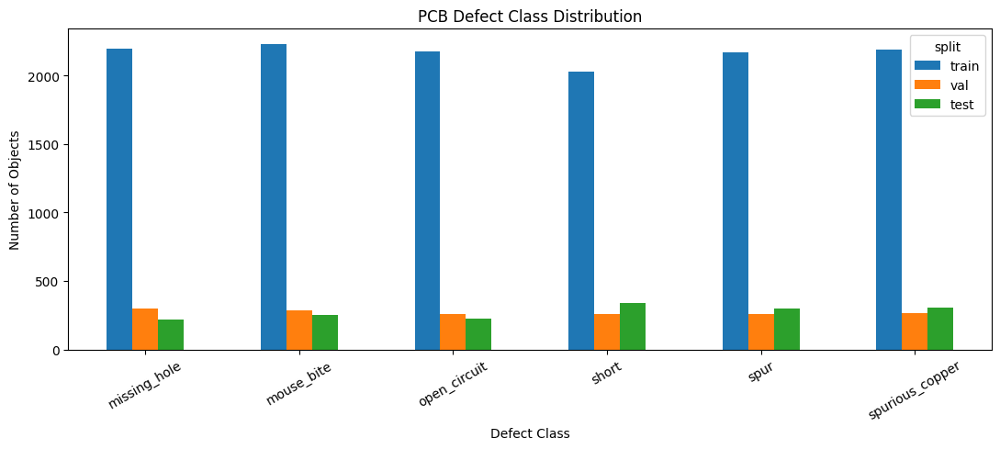

In [20]:
object_records = []

for _, row in images_df.iterrows():

    label_path = Path(row["label_path"])

    with open(label_path, "r") as f:
        lines = f.readlines()

    for line in lines:
        parts = line.strip().split()

        if len(parts) != 5:
            continue

        class_id = int(parts[0])
        xc, yc, w, h = map(float, parts[1:])

        object_records.append({
            "split": row["split"],
            "image_id": row["image_id"],
            "class_id": class_id,
            "class_name": CLASS_NAMES[class_id],
            "x_center": xc,
            "y_center": yc,
            "bbox_width": w,
            "bbox_height": h,
            "image_width": row["width"],
            "image_height": row["height"]
        })

objects_df = pd.DataFrame(object_records)

# Sınıf başına nesne sayısı
class_distribution = pd.crosstab(
    objects_df["class_name"],
    objects_df["split"]
)

class_distribution["total"] = class_distribution.sum(axis=1)

display(class_distribution)

# Sınıf başına pozitif görüntü sayısı
positive_images = (
    objects_df.groupby(["split", "class_name"])["image_id"]
    .nunique()
    .unstack(fill_value=0)
)

print("\nSınıf başına pozitif görüntü sayısı:")
display(positive_images)

# Grafik
class_distribution[["train", "val", "test"]].plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("PCB Defect Class Distribution")
plt.xlabel("Defect Class")
plt.ylabel("Number of Objects")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [21]:
# Orijinal görüntü üzerindeki bbox boyutları
objects_df["bbox_width_px"] = (
    objects_df["bbox_width"] * objects_df["image_width"]
)

objects_df["bbox_height_px"] = (
    objects_df["bbox_height"] * objects_df["image_height"]
)

objects_df["bbox_area_px"] = (
    objects_df["bbox_width_px"] * objects_df["bbox_height_px"]
)

# Bounding box istatistikleri
bbox_stats = (
    objects_df.groupby("class_name")[
        ["bbox_width_px", "bbox_height_px", "bbox_area_px"]
    ]
    .agg(["mean", "median", "min", "max"])
    .round(2)
)

display(bbox_stats)

bbox_width_px                       bbox_height_px         \
                         mean median    min     max           mean median   
class_name                                                                  
missing_hole            29.42  27.00  13.02   69.00          29.25  28.01   
mouse_bite              27.32  27.00  10.98   56.01          27.65  27.00   
open_circuit            22.14  21.00   9.00   52.98          22.55  22.00   
short                   36.21  34.02  13.98  118.02          37.38  34.02   
spur                    32.14  31.01  12.98   73.98          32.74  31.02   
spurious_copper         34.49  31.02   9.98  114.00          34.49  30.00   

                               bbox_area_px                            
                   min     max         mean   median     min      max  
class_name                                                             
missing_hole     13.02   70.02       914.82   752.90  256.64  4201.20  
mouse_bite       10.02   55.02       754.22   665.96  241.78  2021.08  
open_circuit      7.98   54.03       518.88   456.48  131.76  1848.15  
short            13.02  119.00      1441.13  1175.44  234.36  8925.42  
spur             12.00   73.98      1019.02   896.22  256.64  2990.35  
spurious_copper   9.00  115.02      1062.62   950.62  272.02  6082.96

In [23]:
import pandas as pd

# Bounding box boyutlarını piksel cinsinden hesapla
objects_df["bbox_width_px"] = (
    objects_df["bbox_width"] * objects_df["image_width"]
)

objects_df["bbox_height_px"] = (
    objects_df["bbox_height"] * objects_df["image_height"]
)

objects_df["bbox_area_px"] = (
    objects_df["bbox_width_px"] * objects_df["bbox_height_px"]
)

# Tiny object eşikleri
thresholds = [8, 16, 32]

rows = []

for class_name, group in objects_df.groupby("class_name"):

    result = {
        "class_name": class_name,
        "total_objects": len(group)
    }

    for t in thresholds:

        # Hem genişlik hem yükseklik eşikten küçük/eşit
        square_mask = (
            (group["bbox_width_px"] <= t) &
            (group["bbox_height_px"] <= t)
        )

        # Bounding box alanı eşikten küçük/eşit
        area_mask = (
            group["bbox_area_px"] <= t**2
        )

        result[f"both_sides_le_{t}_%"] = round(
            square_mask.mean() * 100, 2
        )

        result[f"area_le_{t*t}_%"] = round(
            area_mask.mean() * 100, 2
        )

    rows.append(result)

tiny_df = pd.DataFrame(rows)

display(tiny_df)

,class_name,total_objects,both_sides_le_8_%,area_le_64_%,both_sides_le_16_%,area_le_256_%,both_sides_le_32_%,area_le_1024_%
0,missing_hole,2709,0.0,0.0,0.00,0.00,64.41,71.28
1,mouse_bite,2763,0.0,0.0,0.00,0.14,54.47,81.76
2,open_circuit,2661,0.0,0.0,4.06,9.96,87.64,94.63
3,short,2631,0.0,0.0,0.00,0.04,28.01,41.62
4,spur,2727,0.0,0.0,0.00,0.00,21.49,60.47
5,spurious_copper,2757,0.0,0.0,0.00,0.00,14.58,55.71


In [25]:
import numpy as np
import pandas as pd

df = objects_df.copy()

# YOLO koordinatları
xc = df["x_center"]
yc = df["y_center"]
w = df["bbox_width"]
h = df["bbox_height"]

# Bounding box köşeleri (normalize)
x1 = xc - w / 2
y1 = yc - h / 2
x2 = xc + w / 2
y2 = yc + h / 2

# Geçerlilik kontrolleri
checks = {
    "NaN / sonsuz koordinat": ~np.isfinite(
        df[["x_center", "y_center", "bbox_width", "bbox_height"]]
    ).all(axis=1),

    "Geçersiz sınıf ID": ~df["class_id"].isin(range(6)),

    "Sıfır veya negatif boyut": (w <= 0) | (h <= 0),

    "Görüntü sınırı dışında": (
        (x1 < -1e-6) |
        (y1 < -1e-6) |
        (x2 > 1 + 1e-6) |
        (y2 > 1 + 1e-6)
    )
}

for name, mask in checks.items():
    print(f"{name}: {mask.sum()}")

print("\nToplam kontrol edilen nesne:", len(df))

invalid_mask = pd.concat(checks, axis=1).any(axis=1)

print("En az bir hatası bulunan nesne:", invalid_mask.sum())

if invalid_mask.any():
    display(df.loc[invalid_mask].head(10))
else:
    print("Tüm bounding box koordinatları geçerli görünüyor.")

NaN / sonsuz koordinat: 0
Geçersiz sınıf ID: 0
Sıfır veya negatif boyut: 0
Görüntü sınırı dışında: 0

Toplam kontrol edilen nesne: 16248
En az bir hatası bulunan nesne: 0
Tüm bounding box koordinatları geçerli görünüyor.


In [26]:
import hashlib
from pathlib import Path

def calculate_hash(image_path):
    sha = hashlib.sha256()

    with open(image_path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha.update(chunk)

    return sha.hexdigest()

hash_df = images_df[["split", "image_id", "image_path"]].copy()

hash_df["hash"] = hash_df["image_path"].apply(calculate_hash)

# Aynı dosya içeriğinin birden fazla split'te bulunması
hash_split_counts = hash_df.groupby("hash")["split"].nunique()

leaked_hashes = hash_split_counts[
    hash_split_counts > 1
].index

leakage_df = hash_df[
    hash_df["hash"].isin(leaked_hashes)
].sort_values("hash")

print("Toplam görüntü:", len(hash_df))
print("Farklı hash sayısı:", hash_df["hash"].nunique())
print("Split'ler arasında ortak hash sayısı:", len(leaked_hashes))
print("Etkilenen görüntü sayısı:", len(leakage_df))

if len(leakage_df) > 0:
    display(leakage_df.head(20))
else:
    print("Birebir aynı dosyadan kaynaklanan split leakage bulunamadı.")

Toplam görüntü: 8001
Farklı hash sayısı: 7971
Split'ler arasında ortak hash sayısı: 9
Etkilenen görüntü sayısı: 36


,split,image_id,image_path,hash
125,train,l_light_01_short_11_1_600,/Users/iremkeser/rtdetr_reproduction/RT-DETR/d...,3c696a92bdc706a87f726c531672be0ac1e83a837d3af3...
7210,test,l_light_01_short_18_1_600,/Users/iremkeser/rtdetr_reproduction/RT-DETR/d...,3c696a92bdc706a87f726c531672be0ac1e83a837d3af3...
128,train,l_light_01_short_12_1_600,/Users/iremkeser/rtdetr_reproduction/RT-DETR/d...,3c696a92bdc706a87f726c531672be0ac1e83a837d3af3...
130,train,l_light_01_short_13_1_600,/Users/iremkeser/rtdetr_reproduction/RT-DETR/d...,3c696a92bdc706a87f726c531672be0ac1e83a837d3af3...
139,train,l_light_01_short_16_1_600,/Users/iremkeser/rtdetr_reproduction/RT-DETR/d...,3c696a92bdc706a87f726c531672be0ac1e83a837d3af3...
145,train,l_light_01_short_19_1_600,/Users/iremkeser/rtdetr_reproduction/RT-DETR/d...,3c696a92bdc706a87f726c531672be0ac1e83a837d3af3...
148,train,l_light_01_short_20_1_600,/Users/iremkeser/rtdetr_reproduction/RT-DETR/d...,3c696a92bdc706a87f726c531672be0ac1e83a837d3af3...
4414,train,rotation_90_light_01_short_20_1_600,/Users/iremkeser/rtdetr_reproduction/RT-DETR/d...,430af9300b15817ca5605fccedd6dfc33b1237ac39144a...
4411,train,rotation_90_light_01_short_19_1_600,/Users/iremkeser/rtdetr_reproduction/RT-DETR/d...,430af9300b15817ca5605fccedd6dfc33b1237ac39144a...
4405,train,rotation_90_light_01_short_16_1_600,/Users/iremkeser/rtdetr_reproduction/RT-DETR/d...,430af9300b15817ca5605fccedd6dfc33b1237ac39144a...


In [27]:
# Split'ler arasında aynı hash'e sahip görüntüler
leakage_details = (
    leakage_df
    .assign(
        filename=lambda df: df["image_path"].apply(
            lambda p: Path(p).name
        )
    )
    .sort_values(["hash", "split", "filename"])
)

# Her hash için görüntü sayısı ve bulunduğu split'ler
leakage_summary = (
    leakage_details
    .groupby("hash")
    .agg(
        image_count=("image_id", "size"),
        splits=("split", lambda x: ", ".join(sorted(set(x)))),
        filenames=("filename", lambda x: list(x))
    )
    .reset_index()
)

display(leakage_summary)

,hash,image_count,splits,filenames
0,3c696a92bdc706a87f726c531672be0ac1e83a837d3af3...,7,"test, train","[l_light_01_short_18_1_600.jpg, l_light_01_sho..."
1,430af9300b15817ca5605fccedd6dfc33b1237ac39144a...,7,"test, train","[rotation_90_light_01_short_18_1_600.jpg, rota..."
2,4bd26863378800abecb2bd4aa8bdf8036ff7542d2276a9...,2,"train, val","[l_light_05_open_circuit_03_1_600.jpg, l_light..."
3,58c0b0988c90216df7ca879ffc4996d04377e8a4afaefa...,3,"test, train","[l_light_01_short_16_2_600.jpg, l_light_01_sho..."
4,6deebed5dbb4ef9168dce4b17519f97f0917ebadc6de2b...,2,"train, val",[rotation_90_light_05_open_circuit_03_1_600.jp...
5,76586d01f91b252fdcf1b5209170112b1d47c31b338153...,3,"test, train","[rotation_90_light_01_short_16_2_600.jpg, rota..."
6,917fff3edf09b89d7a6e82aafa0b3960bb84de565a3e16...,3,"test, train","[rotation_270_light_01_short_16_2_600.jpg, rot..."
7,bdbfdc2962c2b3e41c60050c88b975b03318153c12c122...,7,"test, train","[rotation_270_light_01_short_18_1_600.jpg, rot..."
8,c47fca9432ced54ab5ab4ba54e3eb503caf109dbcf87ed...,2,"train, val",[rotation_270_light_05_open_circuit_03_1_600.j...


In [28]:
for hash_value, group in leakage_details.groupby("hash"):
    print(f"\nHASH: {hash_value[:12]}")
    print("-" * 65)

    for _, row in group.iterrows():
        print(f"{row['split']:6} | {row['filename']}")


HASH: 3c696a92bdc7
-----------------------------------------------------------------
test   | l_light_01_short_18_1_600.jpg
train  | l_light_01_short_11_1_600.jpg
train  | l_light_01_short_12_1_600.jpg
train  | l_light_01_short_13_1_600.jpg
train  | l_light_01_short_16_1_600.jpg
train  | l_light_01_short_19_1_600.jpg
train  | l_light_01_short_20_1_600.jpg

HASH: 430af9300b15
-----------------------------------------------------------------
test   | rotation_90_light_01_short_18_1_600.jpg
train  | rotation_90_light_01_short_11_1_600.jpg
train  | rotation_90_light_01_short_12_1_600.jpg
train  | rotation_90_light_01_short_13_1_600.jpg
train  | rotation_90_light_01_short_16_1_600.jpg
train  | rotation_90_light_01_short_19_1_600.jpg
train  | rotation_90_light_01_short_20_1_600.jpg

HASH: 4bd268633788
-----------------------------------------------------------------
train  | l_light_05_open_circuit_03_1_600.jpg
val    | l_light_05_open_circuit_04_2_600.jpg

HASH: 58c0b0988c90
--------------

In [29]:
from pathlib import Path

def read_yolo_labels(label_path):
    path = Path(label_path)

    if not path.exists():
        return None

    with open(path, "r") as f:
        lines = [
            line.strip()
            for line in f
            if line.strip()
        ]

    return tuple(sorted(lines))


# Hash tablosuna etiket yollarını ekle
label_check_df = hash_df.merge(
    images_df[["split", "image_id", "label_path"]],
    on=["split", "image_id"],
    how="left"
)

# Aynı hash'e sahip görüntüler
duplicate_df = label_check_df[
    label_check_df["hash"].isin(leaked_hashes)
].copy()

duplicate_df["labels"] = (
    duplicate_df["label_path"].apply(read_yolo_labels)
)

for hash_value, group in duplicate_df.groupby("hash"):

    print(f"\nHASH: {hash_value[:12]}")

    print("Görüntü sayısı:", len(group))
    print("Farklı anotasyon sayısı:", group["labels"].nunique())

    for _, row in group.iterrows():
        print(
            f"{row['split']:6} | "
            f"{Path(row['image_path']).name} | "
            f"{row['labels']}"
        )


HASH: 3c696a92bdc7
Görüntü sayısı: 7
Farklı anotasyon sayısı: 7
train  | l_light_01_short_11_1_600.jpg | ('3 0.6700 0.9525 0.0433 0.0483',)
train  | l_light_01_short_12_1_600.jpg | ('3 0.6617 0.9517 0.0533 0.0533',)
train  | l_light_01_short_13_1_600.jpg | ('3 0.6650 0.9517 0.0467 0.0533',)
train  | l_light_01_short_16_1_600.jpg | ('3 0.6708 0.9550 0.0417 0.0467',)
train  | l_light_01_short_19_1_600.jpg | ('3 0.6683 0.9508 0.0400 0.0517',)
train  | l_light_01_short_20_1_600.jpg | ('3 0.6683 0.9567 0.0533 0.0567',)
test   | l_light_01_short_18_1_600.jpg | ('3 0.6692 0.9533 0.0317 0.0367',)

HASH: 430af9300b15
Görüntü sayısı: 7
Farklı anotasyon sayısı: 7
train  | rotation_90_light_01_short_11_1_600.jpg | ('3 0.9533 0.3308 0.0500 0.0450',)
train  | rotation_90_light_01_short_12_1_600.jpg | ('3 0.9525 0.3392 0.0550 0.0550',)
train  | rotation_90_light_01_short_13_1_600.jpg | ('3 0.9525 0.3358 0.0550 0.0483',)
train  | rotation_90_light_01_short_16_1_600.jpg | ('3 0.9558 0.3300 0.0483 0.04

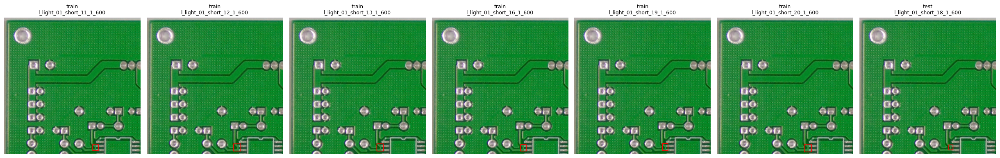

In [32]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# İlk problemli hash grubunu seç
selected_hash = leakage_details["hash"].iloc[0]

group = duplicate_df[
    duplicate_df["hash"] == selected_hash
].copy()

fig, axes = plt.subplots(
    1, len(group),
    figsize=(3.5 * len(group), 4)
)

for ax, (_, row) in zip(axes, group.iterrows()):

    image = cv2.imread(str(row["image_path"]))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    h, w = image.shape[:2]

    for label in row["labels"]:
        cls, xc, yc, bw, bh = map(float, label.split())

        x1 = int((xc - bw / 2) * w)
        y1 = int((yc - bh / 2) * h)
        x2 = int((xc + bw / 2) * w)
        y2 = int((yc + bh / 2) * h)

        cv2.rectangle(
            image, (x1, y1), (x2, y2),
            (255, 0, 0), 2
        )

    ax.imshow(image)
    ax.set_title(
        f"{row['split']}\n"
        f"{Path(row['image_path']).stem[:25]}",
        fontsize=9
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

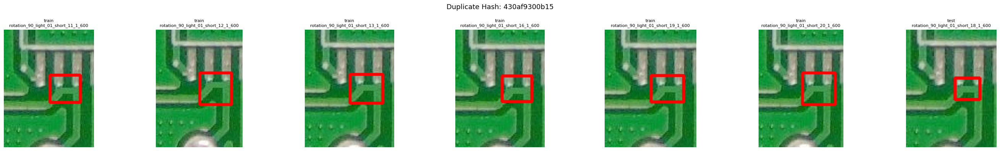

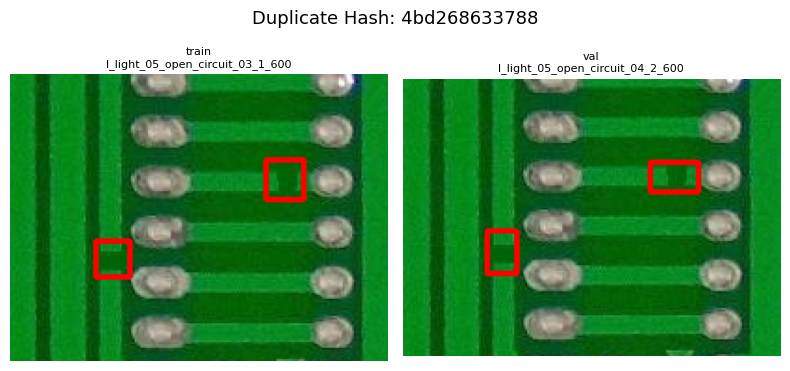

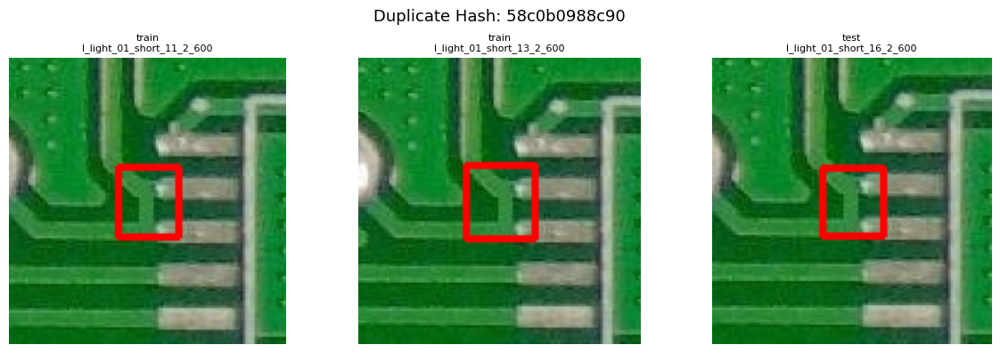

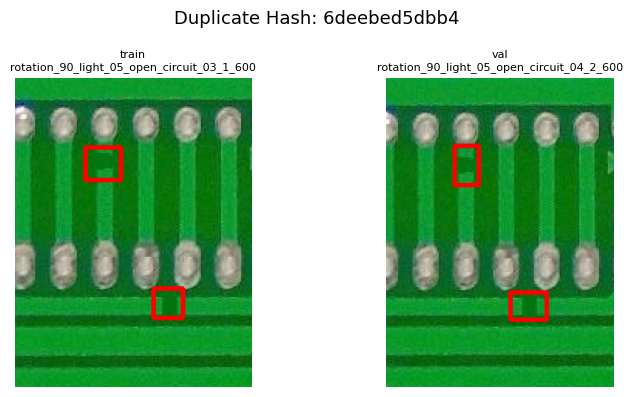

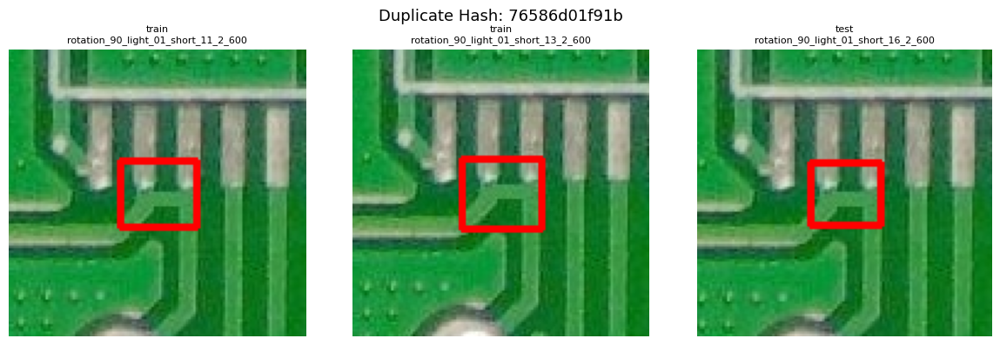

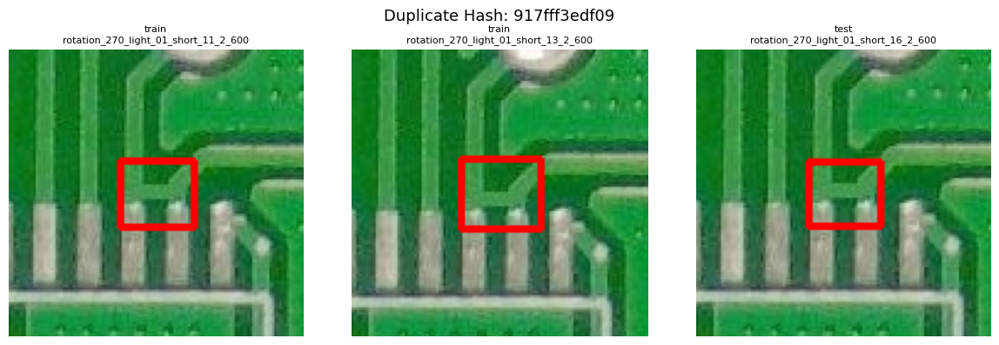

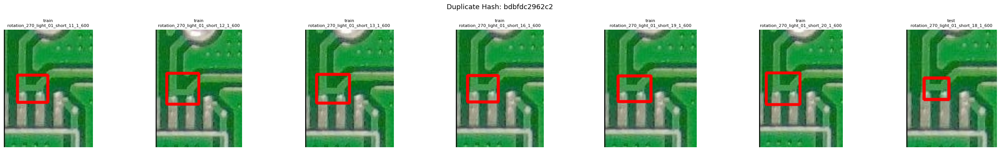

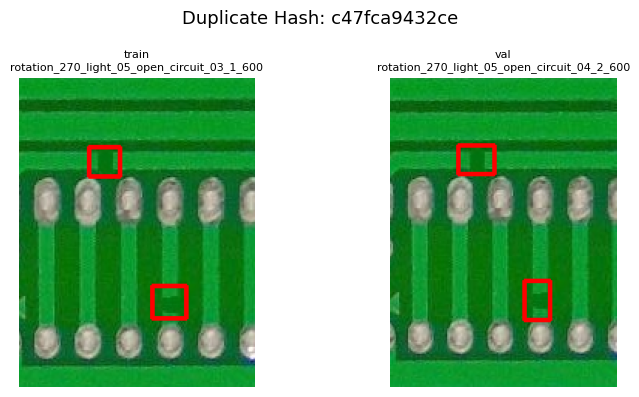

In [33]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# Daha önce incelediğimiz ilk hash'i atla
remaining_hashes = list(leaked_hashes)[1:]

for hash_value in remaining_hashes:

    group = duplicate_df[
        duplicate_df["hash"] == hash_value
    ].copy()

    n = len(group)

    fig, axes = plt.subplots(
        1, n,
        figsize=(4 * n, 4),
        squeeze=False
    )

    axes = axes[0]

    for ax, (_, row) in zip(axes, group.iterrows()):

        image = cv2.imread(str(row["image_path"]))
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        h, w = image.shape[:2]

        boxes = []

        for label in row["labels"]:
            cls, xc, yc, bw, bh = map(float, label.split())

            x1 = int((xc - bw / 2) * w)
            y1 = int((yc - bh / 2) * h)
            x2 = int((xc + bw / 2) * w)
            y2 = int((yc + bh / 2) * h)

            boxes.append((x1, y1, x2, y2))

            cv2.rectangle(
                image,
                (x1, y1),
                (x2, y2),
                (255, 0, 0),
                2
            )

        # Kusurların bulunduğu bölgeye yakınlaş
        margin = 45

        crop_x1 = max(0, min(b[0] for b in boxes) - margin)
        crop_y1 = max(0, min(b[1] for b in boxes) - margin)
        crop_x2 = min(w, max(b[2] for b in boxes) + margin)
        crop_y2 = min(h, max(b[3] for b in boxes) + margin)

        cropped = image[crop_y1:crop_y2, crop_x1:crop_x2]

        ax.imshow(cropped)

        ax.set_title(
            f"{row['split']}\n"
            f"{Path(row['image_path']).stem}",
            fontsize=8
        )

        ax.axis("off")

    fig.suptitle(
        f"Duplicate Hash: {hash_value[:12]}",
        fontsize=13
    )

    plt.tight_layout()
    plt.show()

In [34]:
# Aynı hash'e sahip görüntülerden birini tut
# Öncelik: train > val > test

split_priority = {"train": 0, "val": 1, "test": 2}

dedup_df = hash_df.copy()

dedup_df["priority"] = (
    dedup_df["split"].map(split_priority)
)

dedup_df = (
    dedup_df
    .sort_values(["priority", "image_id"])
    .drop_duplicates(subset="hash", keep="first")
    .drop(columns="priority")
    .reset_index(drop=True)
)

print("Önceki görüntü sayısı:", len(hash_df))
print("Tekilleştirme sonrası:", len(dedup_df))
print("Kaldırılacak tekrar:", len(hash_df) - len(dedup_df))

print("\nSplit dağılımı:")
print(dedup_df["split"].value_counts())

Önceki görüntü sayısı: 8001
Tekilleştirme sonrası: 7971
Kaldırılacak tekrar: 30

Split dağılımı:
split
train    6378
val       798
test      795
Name: count, dtype: int64


In [35]:
from pathlib import Path
import re

# Tekilleştirilmiş görüntüler
name_df = dedup_df.copy()

name_df["filename"] = name_df["image_path"].apply(
    lambda p: Path(p).stem
)

# Dönüşüm öneklerini kaldır
name_df["source_name"] = name_df["filename"].str.replace(
    r"^(rotation_90_|rotation_270_|l_)",
    "",
    regex=True
)

# Işıklandırma bilgisini ayır
name_df["light"] = name_df["source_name"].str.extract(
    r"^(light_\d+)"
)

# Işıklandırma bilgisini kaldır
name_df["without_light"] = name_df["source_name"].str.replace(
    r"^light_\d+_",
    "",
    regex=True
)

print("Toplam görüntü:", len(name_df))
print("Farklı source_name:", name_df["source_name"].nunique())
print("Farklı without_light:", name_df["without_light"].nunique())

print("\nIşıklandırma dağılımı:")
display(name_df["light"].value_counts())

print("\nÖrnek dosya isimleri:")
display(
    name_df[
        ["split", "filename", "source_name", "without_light"]
    ].head(15)
)

Toplam görüntü: 7971
Farklı source_name: 2657
Farklı without_light: 521

Işıklandırma dağılımı:


light
light_04    1275
light_11     855
light_08     843
light_12     819
light_09     792
light_07     765
light_06     762
light_01     723
light_05     708
light_10     429
Name: count, dtype: int64


Örnek dosya isimleri:


,split,filename,source_name,without_light
0,train,l_light_01_missing_hole_01_1_600,light_01_missing_hole_01_1_600,missing_hole_01_1_600
1,train,l_light_01_missing_hole_01_2_600,light_01_missing_hole_01_2_600,missing_hole_01_2_600
2,train,l_light_01_missing_hole_02_2_600,light_01_missing_hole_02_2_600,missing_hole_02_2_600
3,train,l_light_01_missing_hole_02_3_600,light_01_missing_hole_02_3_600,missing_hole_02_3_600
4,train,l_light_01_missing_hole_03_1_600,light_01_missing_hole_03_1_600,missing_hole_03_1_600
5,train,l_light_01_missing_hole_03_2_600,light_01_missing_hole_03_2_600,missing_hole_03_2_600
6,train,l_light_01_missing_hole_04_1_600,light_01_missing_hole_04_1_600,missing_hole_04_1_600
7,train,l_light_01_missing_hole_04_2_600,light_01_missing_hole_04_2_600,missing_hole_04_2_600
8,train,l_light_01_missing_hole_05_1_600,light_01_missing_hole_05_1_600,missing_hole_05_1_600
9,train,l_light_01_missing_hole_05_2_600,light_01_missing_hole_05_2_600,missing_hole_05_2_600


In [36]:
# Her without_light grubu kaç farklı split'te bulunuyor?
group_split_counts = (
    name_df.groupby("without_light")["split"]
    .nunique()
)

# Birden fazla split'te bulunan gruplar
leaked_groups = group_split_counts[
    group_split_counts > 1
].index

# Bu gruplardaki görüntüler
light_leakage_df = name_df[
    name_df["without_light"].isin(leaked_groups)
].copy()

print("Toplam without_light grubu:",
      name_df["without_light"].nunique())

print("Birden fazla split'te bulunan grup:",
      len(leaked_groups))

print("Bu gruplardaki görüntü sayısı:",
      len(light_leakage_df))

# Grupların hangi split'lerde bulunduğunu göster
leakage_summary = (
    light_leakage_df.groupby("without_light")
    .agg(
        image_count=("image_id", "size"),
        light_count=("light", "nunique"),
        split_count=("split", "nunique"),
        splits=("split", lambda x: ", ".join(sorted(set(x))))
    )
    .sort_values("image_count", ascending=False)
)

display(leakage_summary.head(20))

Toplam without_light grubu: 521
Birden fazla split'te bulunan grup: 269
Bu gruplardaki görüntü sayısı: 5838


,image_count,light_count,split_count,splits
without_light,,,,
missing_hole_01_1_600,30,10,2,"train, val"
mouse_bite_05_2_600,30,10,2,"test, train"
spurious_copper_01_1_600,30,10,3,"test, train, val"
spur_05_2_600,30,10,3,"test, train, val"
spur_05_1_600,30,10,3,"test, train, val"
mouse_bite_01_3_600,30,10,2,"train, val"
mouse_bite_02_1_600,30,10,3,"test, train, val"
mouse_bite_02_2_600,30,10,2,"train, val"
spur_01_2_600,30,10,3,"test, train, val"


Farklı ışıklandırma sayısı: 10


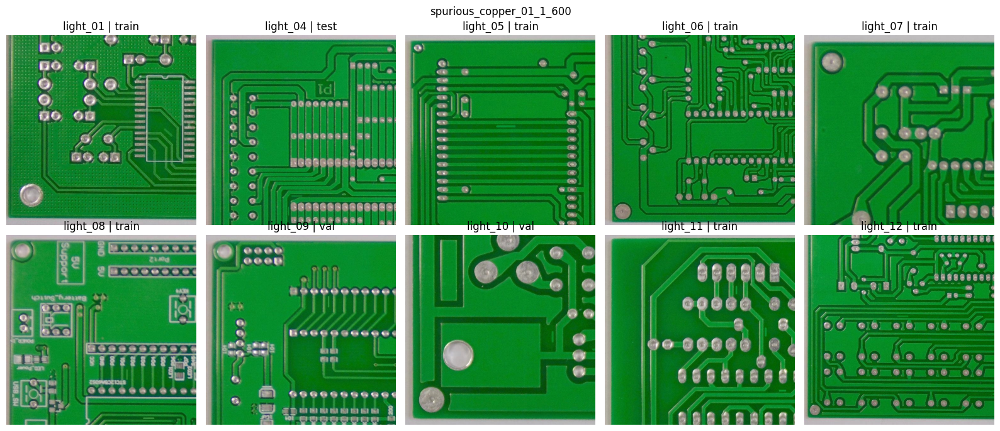

In [37]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

selected_group = "spurious_copper_01_1_600"

samples = name_df[
    (name_df["without_light"] == selected_group) &
    (name_df["filename"].str.startswith("l_"))
].sort_values("light")

print("Farklı ışıklandırma sayısı:", len(samples))

fig, axes = plt.subplots(2, 5, figsize=(16, 7))

for ax, (_, row) in zip(axes.flat, samples.iterrows()):
    image = cv2.imread(str(row["image_path"]))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    ax.imshow(image)
    ax.set_title(f"{row['light']} | {row['split']}")
    ax.axis("off")

for ax in axes.flat[len(samples):]:
    ax.axis("off")

plt.suptitle(selected_group)
plt.tight_layout()
plt.show()

In [38]:
import imagehash
from PIL import Image
import pandas as pd

# Tekilleştirdiğimiz veri setini kullanıyoruz
phash_df = dedup_df.copy()

def calculate_phash(image_path):
    with Image.open(image_path) as img:
        return imagehash.phash(img.convert("L"))

phash_df["phash"] = phash_df["image_path"].apply(
    calculate_phash
)

print("Toplam görüntü:", len(phash_df))
print("Benzersiz pHash:", phash_df["phash"].nunique())

Toplam görüntü: 7971
Benzersiz pHash: 954


In [39]:
from pathlib import Path

# 1. Mevcut görüntülerde light_XX dağılımı
print("LIGHT GRUPLARI")
print(
    name_df.groupby("light")
    .agg(
        image_count=("image_id", "count"),
        unique_sources=("source_name", "nunique"),
        unique_patterns=("without_light", "nunique")
    )
    .to_string()
)

# 2. Veri setinde referans PCB görüntüleri var mı?
# image_path üzerinden veri setinin üst dizinine çıkıyoruz.
sample_path = Path(name_df["image_path"].iloc[0])

print("\nÖRNEK GÖRÜNTÜ YOLU:")
print(sample_path)

print("\nÜST DİZİNLER:")
for parent in list(sample_path.parents)[:5]:
    print(parent)

# 3. İlk aşamada yalnızca örnek dosya isimlerini inceleyelim
print("\nHER LIGHT GRUBUNDAN 3 ÖRNEK:")
for light, group in name_df.groupby("light"):
    print(f"\n{light}:")
    for filename in group["filename"].head(3):
        print(" ", filename)

LIGHT GRUPLARI
          image_count  unique_sources  unique_patterns
light                                                 
light_01          723             241              241
light_04         1275             425              425
light_05          708             236              236
light_06          762             254              254
light_07          765             255              255
light_08          843             281              281
light_09          792             264              264
light_10          429             143              143
light_11          855             285              285
light_12          819             273              273

ÖRNEK GÖRÜNTÜ YOLU:
/Users/iremkeser/rtdetr_reproduction/RT-DETR/data/raw/pcb_clean_split/train/images/l_light_01_missing_hole_01_1_600.jpg

ÜST DİZİNLER:
/Users/iremkeser/rtdetr_reproduction/RT-DETR/data/raw/pcb_clean_split/train/images
/Users/iremkeser/rtdetr_reproduction/RT-DETR/data/raw/pcb_clean_split/train
/Users/ire

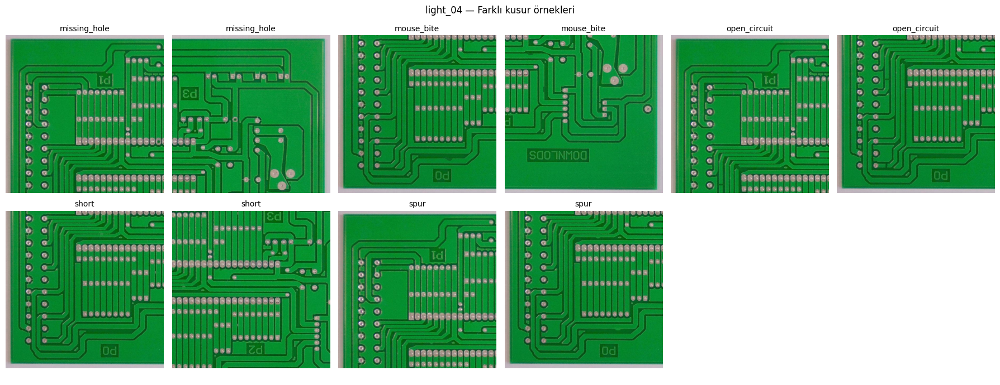

In [40]:
import cv2
import matplotlib.pyplot as plt

selected_light = "light_04"

# Sadece orijinal yönelimli görüntüler
samples = name_df[
    (name_df["light"] == selected_light) &
    (name_df["filename"].str.startswith("l_"))
].copy()

# Farklı kusur sınıflarından örnekler seç
samples["defect_type"] = samples["without_light"].str.extract(
    r"^(missing_hole|mouse_bite|open_circuit|short|spur|spurious_copper)"
)

samples = (
    samples.groupby("defect_type", group_keys=False)
    .head(2)
    .sort_values("defect_type")
)

fig, axes = plt.subplots(2, 6, figsize=(18, 7))

for ax, (_, row) in zip(axes.flat, samples.iterrows()):
    img = cv2.imread(str(row["image_path"]))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    ax.imshow(img)
    ax.set_title(row["defect_type"], fontsize=10)
    ax.axis("off")

for ax in axes.flat[len(samples):]:
    ax.axis("off")

plt.suptitle(f"{selected_light} — Farklı kusur örnekleri")
plt.tight_layout()
plt.show()

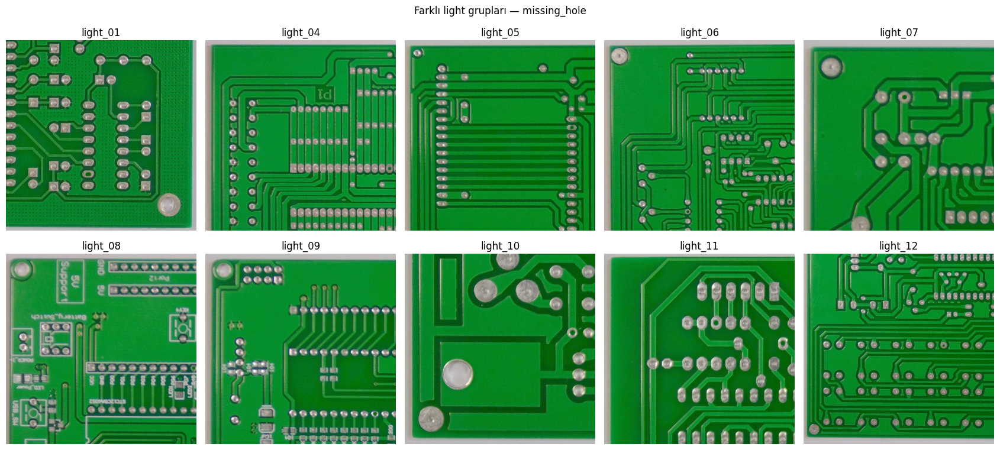

In [41]:
import cv2
import matplotlib.pyplot as plt

selected_defect = "missing_hole"

samples = name_df[
    name_df["filename"].str.startswith("l_") &
    name_df["without_light"].str.startswith(selected_defect + "_")
].copy()

# Her light grubundan bir örnek
samples = (
    samples.sort_values("filename")
    .groupby("light", group_keys=False)
    .head(1)
    .sort_values("light")
)

fig, axes = plt.subplots(2, 5, figsize=(17, 8))

for ax, (_, row) in zip(axes.flat, samples.iterrows()):
    img = cv2.imread(str(row["image_path"]))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    ax.imshow(img)
    ax.set_title(row["light"])
    ax.axis("off")

for ax in axes.flat[len(samples):]:
    ax.axis("off")

plt.suptitle("Farklı light grupları — missing_hole")
plt.tight_layout()
plt.show()

In [42]:
# PCB tasarım gruplarının mevcut split dağılımı

light_split_table = pd.crosstab(
    name_df["light"],
    name_df["split"]
)

light_split_table["total"] = light_split_table.sum(axis=1)

display(light_split_table)

print(
    "\nBirden fazla split'te bulunan light grubu:",
    (light_split_table[["train", "val", "test"]] > 0)
    .sum(axis=1)
    .gt(1)
    .sum()
)

split,test,train,val,total
light,,,,
light_01,39,615,69,723
light_04,129,1005,141,1275
light_05,72,579,57,708
light_06,84,612,66,762
light_07,96,576,93,765
light_08,78,675,90,843
light_09,75,639,78,792
light_10,42,339,48,429
light_11,96,669,90,855



Birden fazla split'te bulunan light grubu: 10


In [44]:
# Aynı kaynak görüntünün farklı split'lerdeki varyantlarını bul

variant_check = (
    name_df.groupby("source_name")
    .agg(
        image_count=("image_id", "count"),
        split_count=("split", "nunique"),
        splits=("split", lambda x: sorted(x.unique()))
    )
)

variant_leakage = variant_check[
    variant_check["split_count"] > 1
]

print("Toplam kaynak görüntü:", len(variant_check))
print("Farklı split'lere dağılan kaynak:", len(variant_leakage))

# Sorunlu kaynakların tüm varyantlarını göster
leaked_variants = name_df[
    name_df["source_name"].isin(variant_leakage.index)
].copy()

display(
    leaked_variants[
        ["source_name", "filename", "split", "hash"]
    ].sort_values(
        ["source_name", "split", "filename"]
    )
)

Toplam kaynak görüntü: 2657
Farklı split'lere dağılan kaynak: 0


,source_name,filename,split,hash


In [45]:
# Tekilleştirme sonrası kalan görüntülerin anotasyonlarını seç

clean_objects_df = objects_df.merge(
    dedup_df[["split", "image_id"]],
    on=["split", "image_id"],
    how="inner"
)

class_distribution = pd.crosstab(
    clean_objects_df["class_name"],
    clean_objects_df["split"]
)

class_distribution["total"] = class_distribution.sum(axis=1)

display(class_distribution)

print("Toplam nesne sayısı:", len(clean_objects_df))

split,test,train,val,total
class_name,,,,
missing_hole,216,2193,300,2709
mouse_bite,252,2229,282,2763
open_circuit,228,2178,249,2655
short,336,2007,258,2601
spur,300,2169,258,2727
spurious_copper,303,2190,264,2757


Toplam nesne sayısı: 16212


In [46]:
# Orijinal 8001 görüntülük çalışma seti üzerinde
# SHA-256 ve rotasyon leakage kontrolü

audit_df = hash_df.copy()

audit_df["source_name"] = (
    audit_df["image_id"]
    .str.replace(r"\.(jpg|jpeg|png)$", "", regex=True, case=False)
    .str.replace(
        r"^(rotation_90_|rotation_270_|l_)",
        "",
        regex=True
    )
)

# SHA-256: Aynı görüntü farklı split'lerde mi?
sha_leak = (
    audit_df.groupby("hash")["split"]
    .nunique()
    .gt(1)
)

# Kaynak görüntü: Rotasyon varyantları farklı split'lerde mi?
source_leak = (
    audit_df.groupby("source_name")["split"]
    .nunique()
    .gt(1)
)

print("Toplam görüntü:", len(audit_df))
print("Benzersiz SHA-256:", audit_df["hash"].nunique())
print("Split'ler arasında ortak SHA-256:", sha_leak.sum())
print("Split'ler arasında ortak kaynak:", source_leak.sum())

print("\nTekilleştirme sonrası kontrol:")

print(
    "Tekrarlanan SHA-256:",
    dedup_df["hash"].duplicated().sum()
)

print(
    "Farklı split'lerdeki rotasyon kaynakları:",
    variant_leakage.shape[0]
)

Toplam görüntü: 8001
Benzersiz SHA-256: 7971
Split'ler arasında ortak SHA-256: 9
Split'ler arasında ortak kaynak: 0

Tekilleştirme sonrası kontrol:
Tekrarlanan SHA-256: 0
Farklı split'lerdeki rotasyon kaynakları: 0


Görüntü 1: l_light_04_mouse_bite_01_1_600 | train
Görüntü 2: l_light_04_short_01_1_600 | test
ORB keypoint sayıları: 1984 2000
İyi eşleşme sayısı: 503


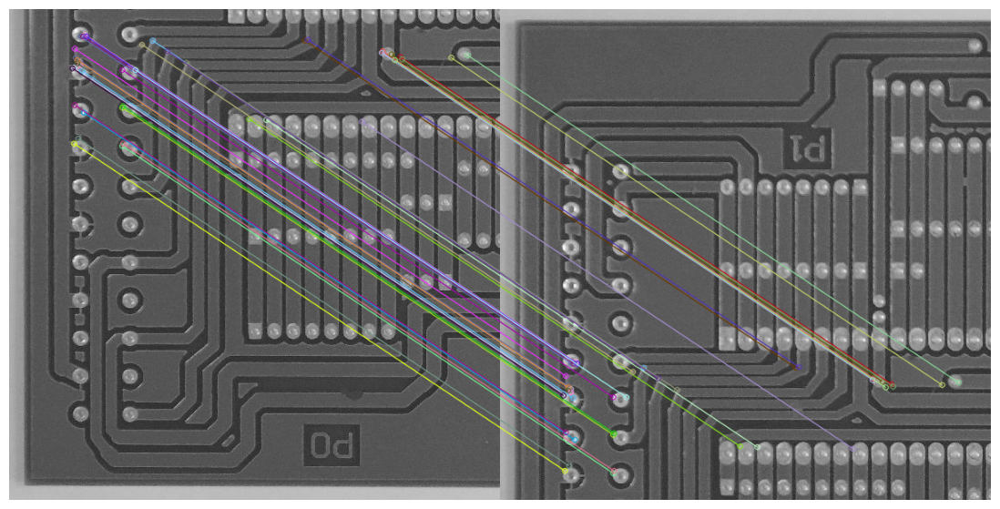

In [48]:
import cv2
import matplotlib.pyplot as plt

# Aynı PCB tasarımından farklı kusur ve split örnekleri
group = name_df[
    (name_df["light"] == "light_04") &
    (name_df["filename"].str.startswith("l_"))
].copy()

img1_row = group[
    (group["without_light"].str.startswith("mouse_bite_")) &
    (group["split"] == "train")
].iloc[0]

img2_row = group[
    (group["without_light"].str.startswith("short_")) &
    (group["split"] == "test")
].iloc[0]

img1 = cv2.imread(str(img1_row["image_path"]), cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread(str(img2_row["image_path"]), cv2.IMREAD_GRAYSCALE)

# ORB
orb = cv2.ORB_create(nfeatures=2000)

kp1, des1 = orb.detectAndCompute(img1, None)
kp2, des2 = orb.detectAndCompute(img2, None)

# Descriptor matching
good_matches = []

if des1 is not None and des2 is not None:
    bf = cv2.BFMatcher(cv2.NORM_HAMMING)

    matches = bf.knnMatch(des1, des2, k=2)

    for pair in matches:
        if len(pair) == 2:
            m, n = pair

            if m.distance < 0.75 * n.distance:
                good_matches.append(m)

print("Görüntü 1:", img1_row["filename"], "|", img1_row["split"])
print("Görüntü 2:", img2_row["filename"], "|", img2_row["split"])

print("ORB keypoint sayıları:", len(kp1), len(kp2))
print("İyi eşleşme sayısı:", len(good_matches))

# En iyi 40 eşleşmeyi görselleştir
result = cv2.drawMatches(
    img1,
    kp1,
    img2,
    kp2,
    sorted(good_matches, key=lambda x: x.distance)[:40],
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(17, 7))
plt.imshow(result, cmap="gray")
plt.axis("off")
plt.show()

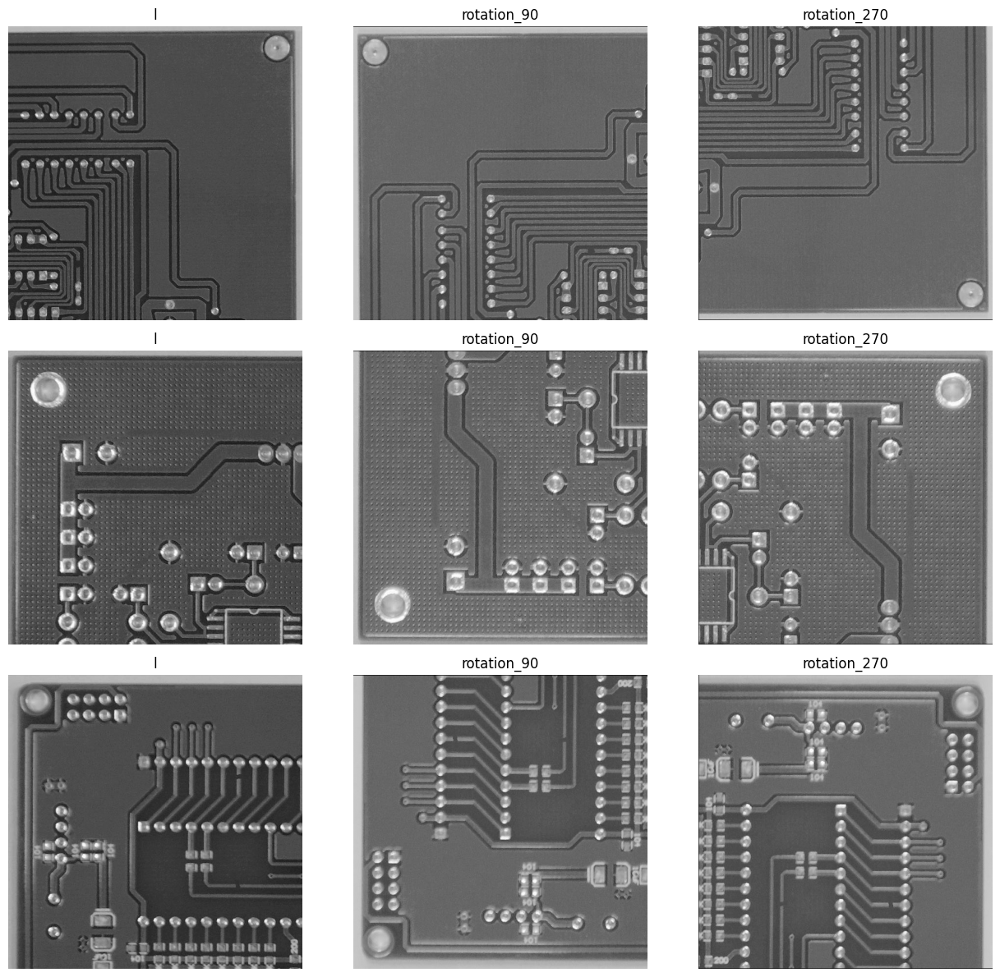

In [49]:
import cv2
import matplotlib.pyplot as plt

# Rastgele 3 rotasyon ailesi
samples = name_df["source_name"].drop_duplicates().sample(
    n=3, random_state=42
)

fig, axes = plt.subplots(3, 3, figsize=(13, 12))

prefixes = ["l_", "rotation_90_", "rotation_270_"]

for row_idx, source in enumerate(samples):
    family = name_df[name_df["source_name"] == source]

    for col_idx, prefix in enumerate(prefixes):
        match = family[
            family["filename"].str.startswith(prefix)
        ]

        ax = axes[row_idx, col_idx]

        if match.empty:
            ax.set_title(f"{prefix} bulunamadı")
            ax.axis("off")
            continue

        image = cv2.imread(
            str(match.iloc[0]["image_path"]),
            cv2.IMREAD_GRAYSCALE
        )

        ax.imshow(image, cmap="gray")
        ax.set_title(prefix.rstrip("_"))
        ax.axis("off")

    axes[row_idx, 0].set_ylabel(
        source, fontsize=9
    )

plt.tight_layout()
plt.show()

In [50]:
from pathlib import Path

# Mevcut temizlenmiş veri setimiz
check_df = name_df.copy()

# 1. Dosya kontrolleri
missing_images = check_df[
    ~check_df["image_path"].apply(lambda p: Path(p).is_file())
]

# image_id -> label_path eşleşmesini mevcut images_df'den al
check_df = check_df.merge(
    images_df[["image_id", "label_path"]].drop_duplicates(),
    on="image_id",
    how="left",
    validate="one_to_one"
)

missing_labels = check_df[
    ~check_df["label_path"].apply(
        lambda p: isinstance(p, (str, Path)) and Path(p).is_file()
    )
]

# 2. SHA-256 tekrarları
duplicate_hashes = check_df["hash"].duplicated().sum()

# 3. Rotasyon ailesi kontrolleri
family_sizes = check_df.groupby("source_name").size()

cross_split_families = (
    check_df.groupby("source_name")["split"]
    .nunique()
    .gt(1)
    .sum()
)

# 4. PCB grupları
light_groups = sorted(check_df["light"].dropna().unique())

print("=== VERİ SETİ DOĞRULAMA ===")
print("Toplam görüntü:", len(check_df))
print("Eksik görüntü:", len(missing_images))
print("Eksik etiket:", len(missing_labels))
print("Tekrarlanan SHA-256:", duplicate_hashes)

print("\n=== ROTASYON AİLELERİ ===")
print("Toplam aile:", len(family_sizes))
print("Üç görüntülü aile:", (family_sizes == 3).sum())
print("Üç görüntülü olmayan aile:", (family_sizes != 3).sum())
print("Split'ler arası ortak aile:", cross_split_families)

print("\n=== PCB GRUPLARI ===")
print("Grup sayısı:", len(light_groups))
print("Gruplar:", light_groups)
print("Grubu belirlenemeyen görüntü:",
      check_df["light"].isna().sum())

print("\n=== SPLIT DAĞILIMI ===")
print(check_df["split"].value_counts().sort_index())

=== VERİ SETİ DOĞRULAMA ===
Toplam görüntü: 7971
Eksik görüntü: 0
Eksik etiket: 0
Tekrarlanan SHA-256: 0

=== ROTASYON AİLELERİ ===
Toplam aile: 2657
Üç görüntülü aile: 2657
Üç görüntülü olmayan aile: 0
Split'ler arası ortak aile: 0

=== PCB GRUPLARI ===
Grup sayısı: 10
Gruplar: ['light_01', 'light_04', 'light_05', 'light_06', 'light_07', 'light_08', 'light_09', 'light_10', 'light_11', 'light_12']
Grubu belirlenemeyen görüntü: 0

=== SPLIT DAĞILIMI ===
split
test      795
train    6378
val       798
Name: count, dtype: int64


In [55]:
from pathlib import Path
import shutil

# Proje ana dizini: RT-DETR/
project_root = Path.cwd().parent

# Veri setinin oluşturulacağı klasör
output_root = project_root / "data" / "processed" / "pcb_random_split"

# Train / Val / Test klasörlerini oluştur
for split in ["train", "val", "test"]:
    (output_root / "images" / split).mkdir(parents=True, exist_ok=True)
    (output_root / "labels" / split).mkdir(parents=True, exist_ok=True)

# Temizlenmiş 7971 görüntüyü ve etiketlerini kopyala
for _, row in check_df.iterrows():
    split = row["split"]

    image_src = Path(row["image_path"])
    label_src = Path(row["label_path"])

    image_dst = output_root / "images" / split / image_src.name
    label_dst = output_root / "labels" / split / label_src.name

    shutil.copy2(image_src, image_dst)
    shutil.copy2(label_src, label_dst)

# Sonuçları kontrol et
print("Veri seti oluşturuldu:", output_root.resolve())

total_images = 0
total_labels = 0

for split in ["train", "val", "test"]:
    image_dir = output_root / "images" / split
    label_dir = output_root / "labels" / split

    n_images = sum(1 for p in image_dir.iterdir() if p.is_file())
    n_labels = sum(1 for p in label_dir.iterdir() if p.is_file())

    total_images += n_images
    total_labels += n_labels

    print(f"{split}: {n_images} görüntü, {n_labels} etiket")

print(f"\nTOPLAM: {total_images} görüntü, {total_labels} etiket")

Veri seti oluşturuldu: /Users/iremkeser/rtdetr_reproduction/RT-DETR/data/processed/pcb_random_split
train: 6378 görüntü, 6378 etiket
val: 798 görüntü, 798 etiket
test: 795 görüntü, 795 etiket

TOPLAM: 7971 görüntü, 7971 etiket


In [57]:
from pathlib import Path
from collections import Counter
import cv2

dataset_root = Path.cwd().parent / "data/processed/pcb_random_split"

sizes = Counter()
invalid_images = []

for split in ["train", "val", "test"]:
    image_dir = dataset_root / "images" / split

    for path in image_dir.iterdir():
        if not path.is_file():
            continue

        img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

        if img is None:
            invalid_images.append(str(path))
            continue

        h, w = img.shape
        sizes[(w, h)] += 1

print("=== GÖRÜNTÜ BOYUTLARI ===")
for (w, h), count in sizes.most_common():
    print(f"{w} x {h}: {count} görüntü")

print("\nOkunamayan görüntü:", len(invalid_images))
print("1024'ü aşan görüntü:",
      sum(n for (w, h), n in sizes.items() if w > 1024 or h > 1024))

=== GÖRÜNTÜ BOYUTLARI ===
600 x 600: 5314 görüntü
601 x 601: 2657 görüntü

Okunamayan görüntü: 0
1024'ü aşan görüntü: 0


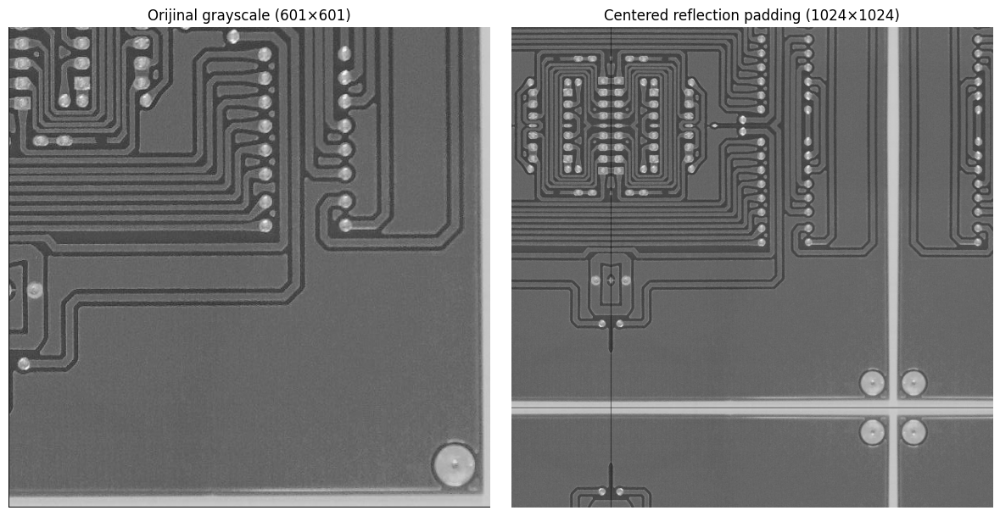

Görüntü: rotation_270_light_06_open_circuit_08_3_600.jpg
Orijinal boyut: (601, 601)
Yeni boyut: (1024, 1024)
Padding: {'left': 211, 'right': 212, 'top': 211, 'bottom': 212}


In [58]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# İlk örnek görüntü
image_path = next(
    (dataset_root / "images" / "train").glob("*.jpg")
)

# 1. Grayscale oku
img = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

h, w = img.shape
target_size = 1024

# 2. Padding miktarları
pad_left = (target_size - w) // 2
pad_right = target_size - w - pad_left

pad_top = (target_size - h) // 2
pad_bottom = target_size - h - pad_top

# 3. Reflection padding
padded = cv2.copyMakeBorder(
    img,
    pad_top,
    pad_bottom,
    pad_left,
    pad_right,
    cv2.BORDER_REFLECT_101
)

# 4. Görselleştir
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(img, cmap="gray", vmin=0, vmax=255)
axes[0].set_title(f"Orijinal grayscale ({w}×{h})")

axes[1].imshow(padded, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Centered reflection padding (1024×1024)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Görüntü:", image_path.name)
print("Orijinal boyut:", img.shape)
print("Yeni boyut:", padded.shape)
print("Padding:", {
    "left": pad_left,
    "right": pad_right,
    "top": pad_top,
    "bottom": pad_bottom
})

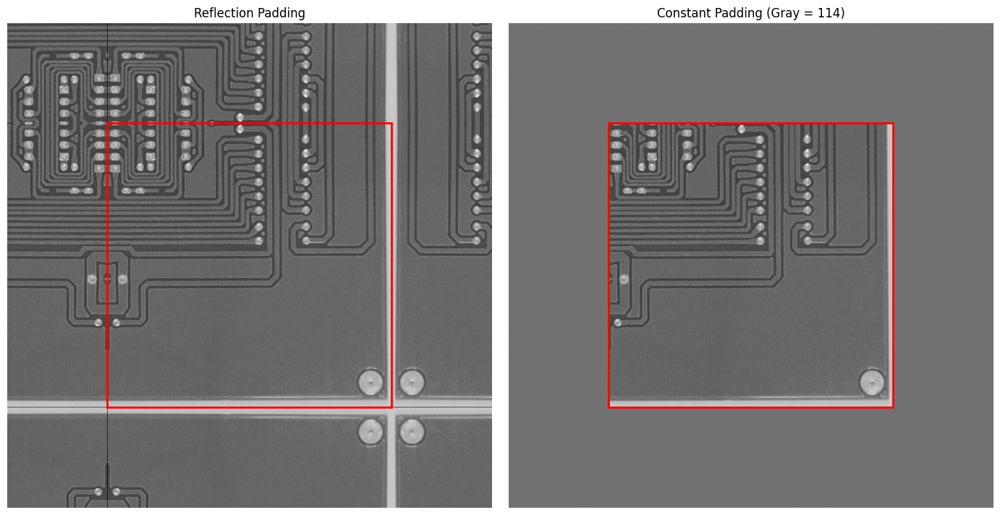

Constant padding boyutu: (1024, 1024)
Orijinal görüntü boyutu: (601, 601)
Padding değeri: 114


In [60]:
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Constant padding: sabit gri arka plan
constant_padded = cv2.copyMakeBorder(
    img,
    pad_top,
    pad_bottom,
    pad_left,
    pad_right,
    borderType=cv2.BORDER_CONSTANT,
    value=114
)

# Reflection ve Constant karşılaştırması
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

for ax, image, title in zip(
    axes,
    [padded, constant_padded],
    ["Reflection Padding", "Constant Padding (Gray = 114)"]
):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)

    # Orijinal görüntünün sınırları
    rect = patches.Rectangle(
        (pad_left - 0.5, pad_top - 0.5),
        w,
        h,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rect)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Constant padding boyutu:", constant_padded.shape)
print("Orijinal görüntü boyutu:", img.shape)
print("Padding değeri:", 114)

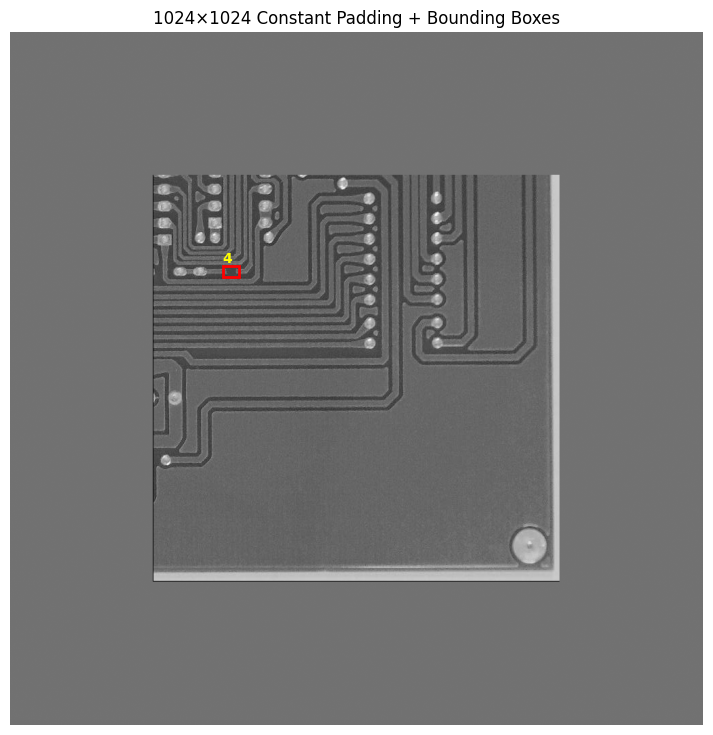

Etiket sayısı: 1
Orijinal boyut: (601, 601)
Yeni boyut: (1024, 1024)


In [61]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

label_path = (
    dataset_root / "labels" / "train" /
    f"{image_path.stem}.txt"
)

fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(constant_padded, cmap="gray", vmin=0, vmax=255)

with open(label_path, "r") as f:
    lines = f.readlines()

for line in lines:
    values = line.strip().split()

    if len(values) != 5:
        continue

    class_id = int(values[0])
    xc, yc, bw, bh = map(float, values[1:])

    # YOLO normalize koordinatları -> orijinal piksel
    xc_px = xc * w
    yc_px = yc * h
    bw_px = bw * w
    bh_px = bh * h

    # Padding sonrası merkez koordinatları
    new_xc = xc_px + pad_left
    new_yc = yc_px + pad_top

    # Bounding box sol üst köşesi
    x1 = new_xc - bw_px / 2
    y1 = new_yc - bh_px / 2

    rect = patches.Rectangle(
        (x1, y1),
        bw_px,
        bh_px,
        fill=False,
        edgecolor="red",
        linewidth=2
    )

    ax.add_patch(rect)
    ax.text(
        x1, y1 - 5,
        str(class_id),
        color="yellow",
        fontsize=10,
        fontweight="bold"
    )

ax.set_title("1024×1024 Constant Padding + Bounding Boxes")
ax.axis("off")
plt.show()

print("Etiket sayısı:", len(lines))
print("Orijinal boyut:", (w, h))
print("Yeni boyut:", constant_padded.shape)

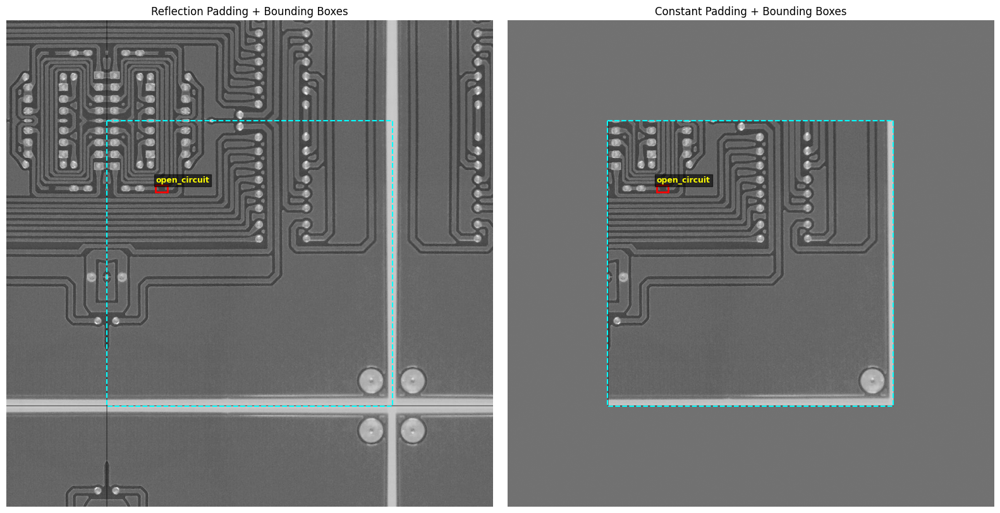

Görüntü: rotation_270_light_06_open_circuit_08_3_600.jpg
Bounding box sayısı: 1


In [63]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Aynı görüntünün etiket dosyası
label_path = (
    dataset_root / "labels" / "train" /
    f"{image_path.stem}.txt"
)

class_names = [
    "mouse_bite",
    "spur",
    "missing_hole",
    "short",
    "open_circuit",
    "spurious_copper"
]

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

images = [padded, constant_padded]
titles = [
    "Reflection Padding + Bounding Boxes",
    "Constant Padding + Bounding Boxes"
]

with open(label_path, "r") as f:
    lines = [line.strip() for line in f if line.strip()]

for ax, image, title in zip(axes, images, titles):

    ax.imshow(image, cmap="gray", vmin=0, vmax=255)

    for line in lines:
        class_id, xc, yc, bw, bh = map(float, line.split())
        class_id = int(class_id)

        # Orijinal normalize YOLO koordinatları -> piksel
        xc_px = xc * w
        yc_px = yc * h
        bw_px = bw * w
        bh_px = bh * h

        # Padding nedeniyle merkez koordinatlarını kaydır
        new_xc = xc_px + pad_left
        new_yc = yc_px + pad_top

        # Bounding box sol üst köşesi
        x1 = new_xc - bw_px / 2
        y1 = new_yc - bh_px / 2

        rect = patches.Rectangle(
            (x1, y1),
            bw_px,
            bh_px,
            fill=False,
            edgecolor="red",
            linewidth=2
        )

        ax.add_patch(rect)

        ax.text(
            x1,
            max(0, y1 - 5),
            class_names[class_id],
            color="yellow",
            fontsize=9,
            fontweight="bold",
            bbox=dict(facecolor="black", alpha=0.6, pad=2)
        )

    # Orijinal görüntünün sınırını göster
    boundary = patches.Rectangle(
        (pad_left - 0.5, pad_top - 0.5),
        w,
        h,
        fill=False,
        edgecolor="cyan",
        linewidth=1.5,
        linestyle="--"
    )

    ax.add_patch(boundary)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Görüntü:", image_path.name)
print("Bounding box sayısı:", len(lines))

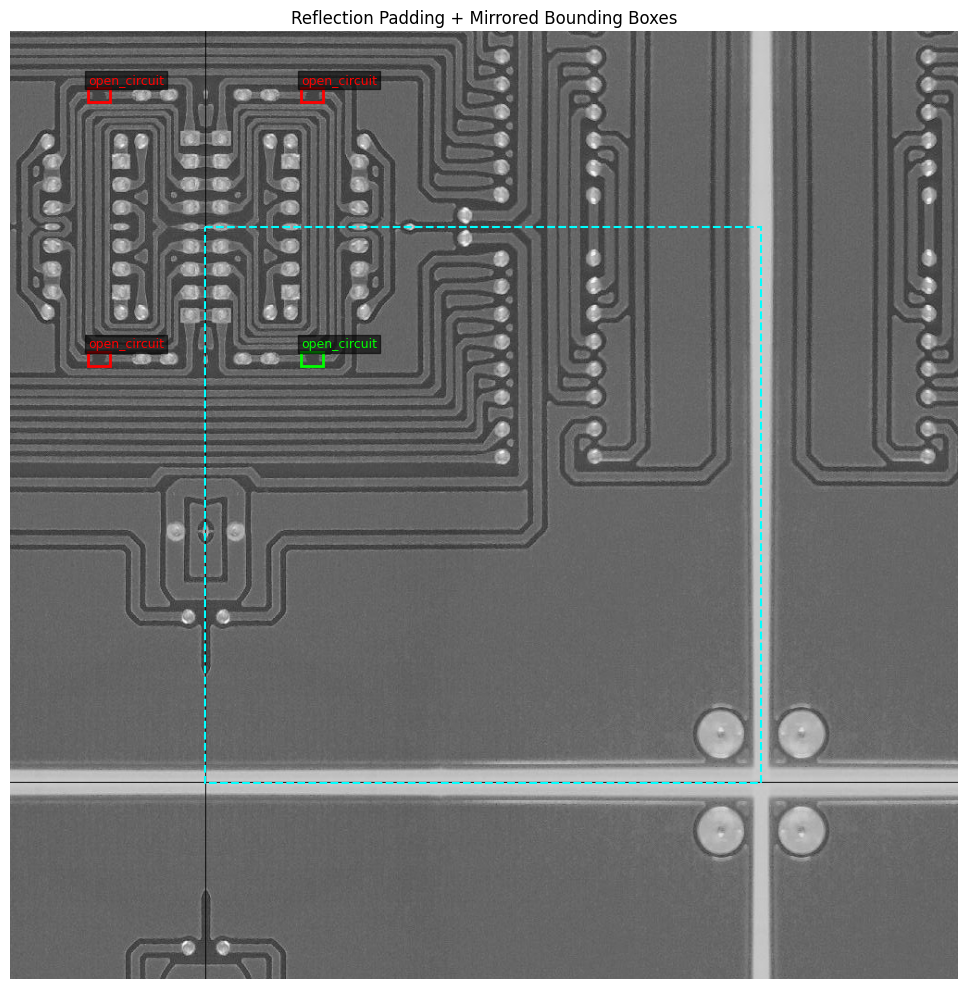

Orijinal bounding box: 1
Toplam çizilen bounding box: 4
Aynalanmış bounding box: 3


In [64]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

class_names = [
    "mouse_bite",
    "spur",
    "missing_hole",
    "short",
    "open_circuit",
    "spurious_copper"
]

# Orijinal görüntü boyutları
h, w = img.shape

# Reflection padding
reflected = cv2.copyMakeBorder(
    img,
    pad_top,
    pad_bottom,
    pad_left,
    pad_right,
    cv2.BORDER_REFLECT_101
)

H, W = reflected.shape

# Orijinal YOLO etiketleri
label_path = (
    dataset_root / "labels" / "train" /
    f"{image_path.stem}.txt"
)

with open(label_path, "r") as f:
    lines = [line.strip() for line in f if line.strip()]

# Her eksende orijinal görüntünün ve yansımaların koordinatları.
# BORDER_REFLECT_101 için yansıma ekseni ilk/son piksel merkezidir.
def reflected_intervals(start, end, length, offset):
    intervals = [
        (start + offset, end + offset, "original"),

        # Sol / üst taraftaki yansıma
        (offset - end, offset - start, "mirror"),

        # Sağ / alt taraftaki yansıma
        (
            offset + 2 * (length - 1) - end,
            offset + 2 * (length - 1) - start,
            "mirror"
        )
    ]
    return intervals

all_boxes = []

for line in lines:
    values = line.split()

    if len(values) != 5:
        continue

    class_id = int(values[0])
    xc, yc, bw, bh = map(float, values[1:])

    # Normalize YOLO -> orijinal piksel koordinatları
    x1 = (xc - bw / 2) * w
    x2 = (xc + bw / 2) * w
    y1 = (yc - bh / 2) * h
    y2 = (yc + bh / 2) * h

    x_intervals = reflected_intervals(x1, x2, w, pad_left)
    y_intervals = reflected_intervals(y1, y2, h, pad_top)

    # Orijinal + yatay/dikey/köşe yansımaları
    for xa, xb, x_type in x_intervals:
        for ya, yb, y_type in y_intervals:

            # Kutuyu 1024x1024 görüntü sınırına kırp
            xa_clip = max(0, xa)
            xb_clip = min(W, xb)
            ya_clip = max(0, ya)
            yb_clip = min(H, yb)

            if xb_clip <= xa_clip or yb_clip <= ya_clip:
                continue

            is_original = (
                x_type == "original" and
                y_type == "original"
            )

            all_boxes.append({
                "class_id": class_id,
                "x1": xa_clip,
                "y1": ya_clip,
                "x2": xb_clip,
                "y2": yb_clip,
                "original": is_original
            })

# Görselleştir
fig, ax = plt.subplots(figsize=(10, 10))

ax.imshow(reflected, cmap="gray", vmin=0, vmax=255)

for box in all_boxes:
    color = "lime" if box["original"] else "red"

    rect = patches.Rectangle(
        (box["x1"], box["y1"]),
        box["x2"] - box["x1"],
        box["y2"] - box["y1"],
        fill=False,
        edgecolor=color,
        linewidth=2
    )

    ax.add_patch(rect)

    ax.text(
        box["x1"],
        max(0, box["y1"] - 5),
        class_names[box["class_id"]],
        color=color,
        fontsize=9,
        bbox=dict(facecolor="black", alpha=0.6, pad=2)
    )

# Orijinal görüntü sınırı
boundary = patches.Rectangle(
    (pad_left - 0.5, pad_top - 0.5),
    w,
    h,
    fill=False,
    edgecolor="cyan",
    linestyle="--",
    linewidth=1.5
)

ax.add_patch(boundary)

ax.set_title("Reflection Padding + Mirrored Bounding Boxes")
ax.axis("off")

plt.tight_layout()
plt.show()

print("Orijinal bounding box:", len(lines))
print("Toplam çizilen bounding box:", len(all_boxes))
print(
    "Aynalanmış bounding box:",
    sum(not b["original"] for b in all_boxes)
)

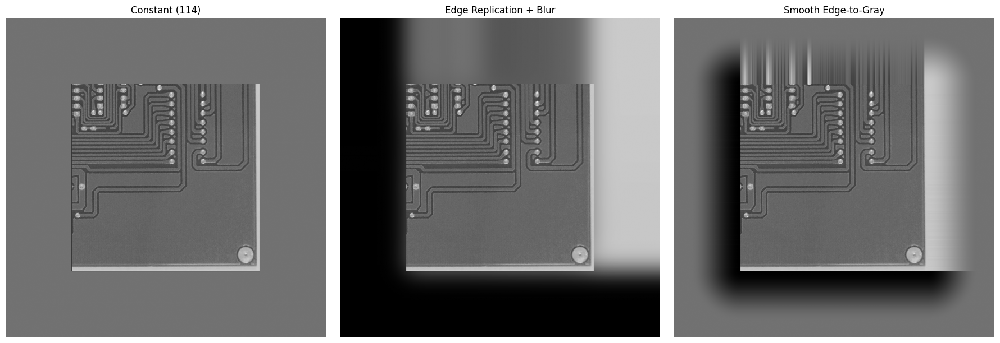

Üç yöntemde de orijinal görüntü pikselleri korundu.
Çıktı boyutu: (1024, 1024)


In [65]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

h, w = img.shape
target = 1024

left = (target - w) // 2
right = target - w - left
top = (target - h) // 2
bottom = target - h - top

# 1. Constant padding
constant = cv2.copyMakeBorder(
    img, top, bottom, left, right,
    cv2.BORDER_CONSTANT, value=114
)

# 2. Edge replication + blur
replicated = cv2.copyMakeBorder(
    img, top, bottom, left, right,
    cv2.BORDER_REPLICATE
)

blurred = cv2.GaussianBlur(
    replicated, (0, 0), sigmaX=35, sigmaY=35
)

# Orijinal görüntüyü bulanıklaştırmadan geri koy
blurred[top:top+h, left:left+w] = img

# 3. Edge replication + dışarı doğru griye geçiş
yy, xx = np.indices((target, target))

dx = np.maximum.reduce([
    left - xx,
    xx - (left + w - 1),
    np.zeros_like(xx)
])

dy = np.maximum.reduce([
    top - yy,
    yy - (top + h - 1),
    np.zeros_like(yy)
])

distance = np.sqrt(dx**2 + dy**2)

# Geçiş mesafesi: 160 piksel
transition = 160

alpha = np.clip(distance / transition, 0, 1)
alpha = alpha * alpha * (3 - 2 * alpha)

smooth = (
    replicated.astype(np.float32) * (1 - alpha)
    + 114 * alpha
).astype(np.uint8)

# Karşılaştırma
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

results = [
    (constant, "Constant (114)"),
    (blurred, "Edge Replication + Blur"),
    (smooth, "Smooth Edge-to-Gray")
]

for ax, (image, title) in zip(axes, results):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Orijinal bölgenin değiştirilmediğini kontrol et
for image, title in [
    (constant, "Constant"),
    (blurred, "Blurred"),
    (smooth, "Smooth")
]:
    assert np.array_equal(
        image[top:top+h, left:left+w], img
    ), f"{title}: Orijinal pikseller değişmiş!"

print("Üç yöntemde de orijinal görüntü pikselleri korundu.")
print("Çıktı boyutu:", smooth.shape)

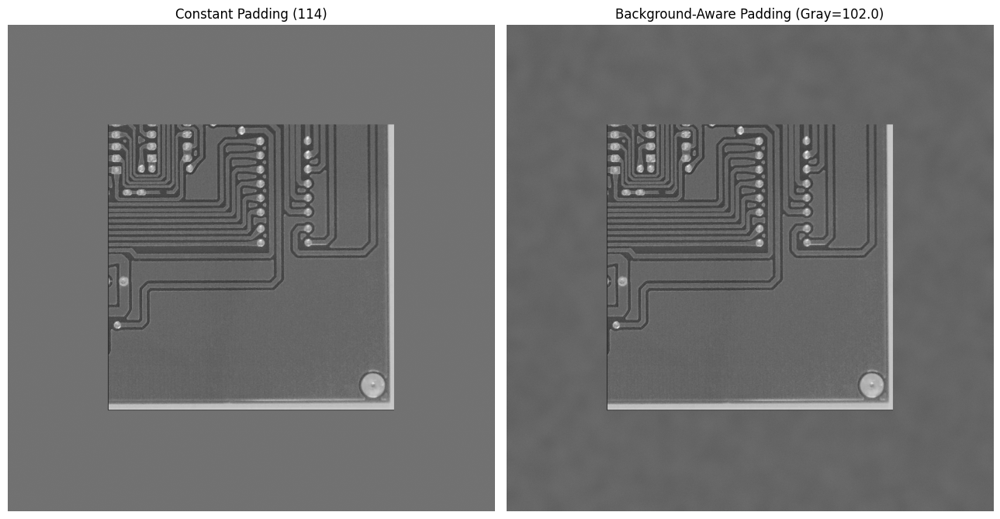

Tahmin edilen arka plan gri değeri: 102.0
Orijinal görüntü korundu: True


In [66]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

h, w = img.shape
target = 1024

left = (target - w) // 2
right = target - w - left
top = (target - h) // 2
bottom = target - h - top

# 1. Arka plan tonunu tahmin et
# Düşük gradyanlı pikseller daha homojen bölgeleri temsil eder.
gray = img.astype(np.float32)

gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)

gradient = cv2.magnitude(gx, gy)

threshold = np.percentile(gradient, 35)
background_pixels = gray[gradient <= threshold]

bg_value = float(np.median(background_pixels))

# 2. Hafif dokulu arka plan oluştur
rng = np.random.default_rng(42)

noise = rng.normal(0, 1, (target, target)).astype(np.float32)

# Yumuşak, düşük frekanslı doku
low_freq = cv2.GaussianBlur(noise, (0, 0), sigmaX=12)

low_freq = low_freq / (low_freq.std() + 1e-6)

# İnce sensör gürültüsüne benzeyen doku
fine_noise = rng.normal(
    0, 1.5, (target, target)
).astype(np.float32)

background = (
    bg_value
    + low_freq * 1.5
    + fine_noise
)

background = np.clip(background, 0, 255).astype(np.uint8)

# 3. Orijinal görüntüyü merkeze yerleştir
background[top:top+h, left:left+w] = img

# 4. Karşılaştırma
fig, axes = plt.subplots(1, 2, figsize=(13, 7))

axes[0].imshow(constant, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Constant Padding (114)")
axes[0].axis("off")

axes[1].imshow(background, cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"Background-Aware Padding (Gray={bg_value:.1f})")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Tahmin edilen arka plan gri değeri:", round(bg_value, 2))
print("Orijinal görüntü korundu:",
      np.array_equal(background[top:top+h, left:left+w], img))